In [ ]:

from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

from pathlib import Path

PROJECT_PATH = Path(
    "/content/drive/MyDrive/ugx-banknote-prototype"
)

print("Project exists:", PROJECT_PATH.exists())

if PROJECT_PATH.exists():
    print("\nProject contents:")
    for item in PROJECT_PATH.iterdir():
        print(item.name)


Project exists: True

Project contents:
requirements.txt
pyproject.toml
README.md
tests
models
src
reports
.venv
data


In [ ]:
import os
from pathlib import Path

PROJECT_PATH = Path(
    "/content/drive/MyDrive/ugx-banknote-prototype"
)

os.chdir(PROJECT_PATH)

print("Working directory:", os.getcwd())
print("Project accessible:", PROJECT_PATH.exists())

Working directory: /content/drive/MyDrive/ugx-banknote-prototype
Project accessible: True


In [ ]:
import torch

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch:", torch.__version__)
print("Selected device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("No GPU assigned. Check Runtime > Change runtime type.")

PyTorch: 2.14.1+cu130
Selected device: cuda
GPU: Tesla T4
CUDA version: 13.0


In [ ]:

from src.banknote.models.baseline_cnn import BanknoteCNN
from src.banknote.ingest.data_loader import create_data_loaders

print("CNN imported successfully!")

train_loader, validation_loader, test_loader = create_data_loaders()

print("Data loaders created successfully!")
print("Training batches:", len(train_loader))
print("Validation batches:", len(validation_loader))
print("Testing batches:", len(test_loader))


CNN imported successfully!
Data loaders created successfully!
Training batches: 125
Validation batches: 27
Testing batches: 27


In [ ]:
!python -m src.banknote.training.train


BASELINE CNN TRAINING
Device: cuda
Epochs: 10
Learning rate: 0.001

Epoch [1/10]
Training Loss: 0.6795 | Training Accuracy: 56.41%
Validation Loss: 0.6084 | Validation Accuracy: 72.90%
Best model checkpoint saved!

Epoch [2/10]
Training Loss: 0.5810 | Training Accuracy: 70.04%
Validation Loss: 0.5415 | Validation Accuracy: 74.77%
Best model checkpoint saved!

Epoch [3/10]
Training Loss: 0.5642 | Training Accuracy: 71.14%
Validation Loss: 0.5024 | Validation Accuracy: 75.23%
Best model checkpoint saved!

Epoch [4/10]
Training Loss: 0.5446 | Training Accuracy: 71.24%
Validation Loss: 0.4885 | Validation Accuracy: 76.17%
Best model checkpoint saved!

Epoch [5/10]
Training Loss: 0.5503 | Training Accuracy: 70.24%
Validation Loss: 0.4797 | Validation Accuracy: 76.17%
Best model checkpoint saved!

Epoch [6/10]
Training Loss: 0.5130 | Training Accuracy: 73.85%
Validation Loss: 0.4223 | Validation Accuracy: 78.50%
Best model checkpoint saved!

Epoch [7/10]
Training Loss: 0.4828 | Training Acc

In [ ]:
!python -m tests.test_resnet


RESNET-18 ARCHITECTURE TEST
----------------------------------------
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100% 44.7M/44.7M [00:00<00:00, 130MB/s]
Input shape: torch.Size([8, 3, 224, 224])
Output shape: torch.Size([8, 2])
Total parameters: 11177538
Trainable parameters: 1026

ResNet-18 test passed!


In [ ]:
!python -m src.banknote.training.train_resnet18



RESNET-18 FEATURE EXTRACTION
Device: cuda
Epochs: 10
Learning rate: 0.001
Random seed: 42

Dataset loaded successfully.
Training batches: 125
Validation batches: 27

Epoch [1/10]
Train Loss: 0.5881
Train Accuracy: 68.94%
Validation Loss: 0.3993
Validation Accuracy: 84.11%
Epoch Time: 599.74 seconds
Best checkpoint saved!

Epoch [2/10]
Train Loss: 0.4338
Train Accuracy: 81.76%
Validation Loss: 0.3603
Validation Accuracy: 87.38%
Epoch Time: 240.83 seconds
Best checkpoint saved!

Epoch [3/10]
Train Loss: 0.3786
Train Accuracy: 84.27%
Validation Loss: 0.3336
Validation Accuracy: 83.64%
Epoch Time: 242.81 seconds
Best checkpoint saved!

Epoch [4/10]
Train Loss: 0.3511
Train Accuracy: 84.57%
Validation Loss: 0.3490
Validation Accuracy: 81.78%
Epoch Time: 242.37 seconds

Epoch [5/10]
Train Loss: 0.3406
Train Accuracy: 85.87%
Validation Loss: 0.3001
Validation Accuracy: 87.38%
Epoch Time: 241.87 seconds
Best checkpoint saved!

Epoch [6/10]
Train Loss: 0.3267
Train Accuracy: 85.47%
Validation 

#  VISUALISATION LABORATORY

Exploring the dataset, preprocessing pipeline, CNN architecture,
feature maps, training behaviour and model predictions.

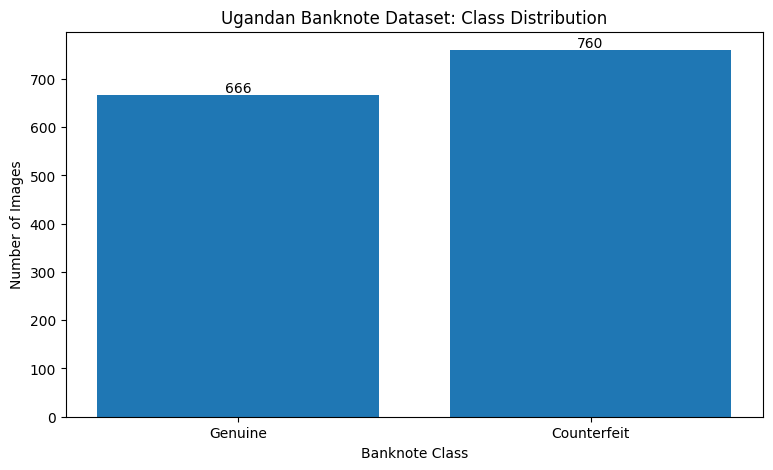

Total images: 1426


In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Locate the dataset
DATASET_PATH = next(
    PROJECT_PATH.glob(
        "data/raw/Ugandan banknote*/labelled_ugandan_banknote_dataset_clean"
    )
)

genuine_folder = DATASET_PATH / "all_images" / "genuine"
counterfeit_folder = DATASET_PATH / "all_images" / "counterfeit"

# Count images
genuine_count = len(list(genuine_folder.glob("*")))
counterfeit_count = len(list(counterfeit_folder.glob("*")))

labels = ["Genuine", "Counterfeit"]
counts = [genuine_count, counterfeit_count]

# Plot
plt.figure(figsize=(9, 5))

bars = plt.bar(
    labels,
    counts
)

plt.title("Ugandan Banknote Dataset: Class Distribution")
plt.xlabel("Banknote Class")
plt.ylabel("Number of Images")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        str(int(height)),
        ha="center",
        va="bottom"
    )

plt.show()

print("Total images:", sum(counts))


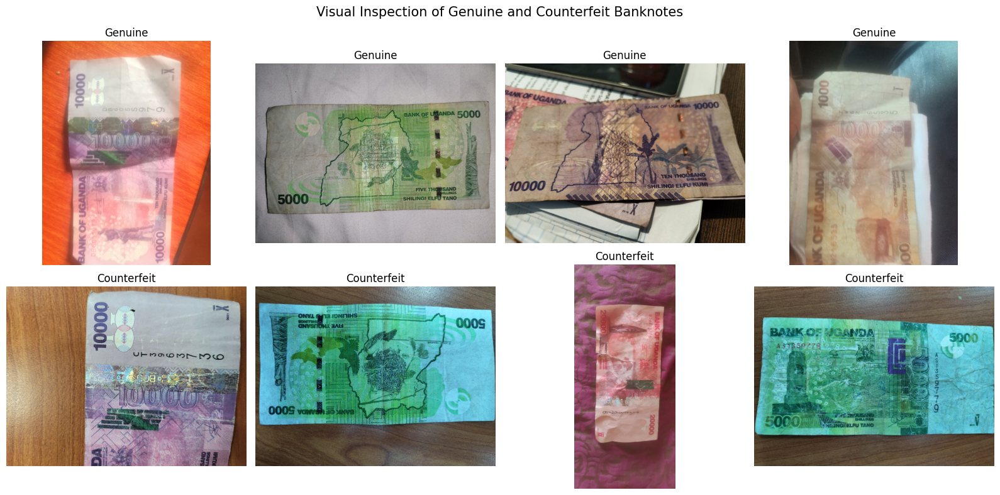

In [ ]:

import random
from PIL import Image

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

folders = [
    ("Genuine", genuine_folder),
    ("Counterfeit", counterfeit_folder)
]

for row, (label, folder) in enumerate(folders):

    image_paths = [
        p for p in folder.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    samples = random.sample(image_paths, 4)

    for col, image_path in enumerate(samples):

        image = Image.open(image_path).convert("RGB")

        axes[row, col].imshow(image)
        axes[row, col].set_title(label)
        axes[row, col].axis("off")

plt.suptitle(
    "Visual Inspection of Genuine and Counterfeit Banknotes",
    fontsize=15
)

plt.tight_layout()
plt.show()


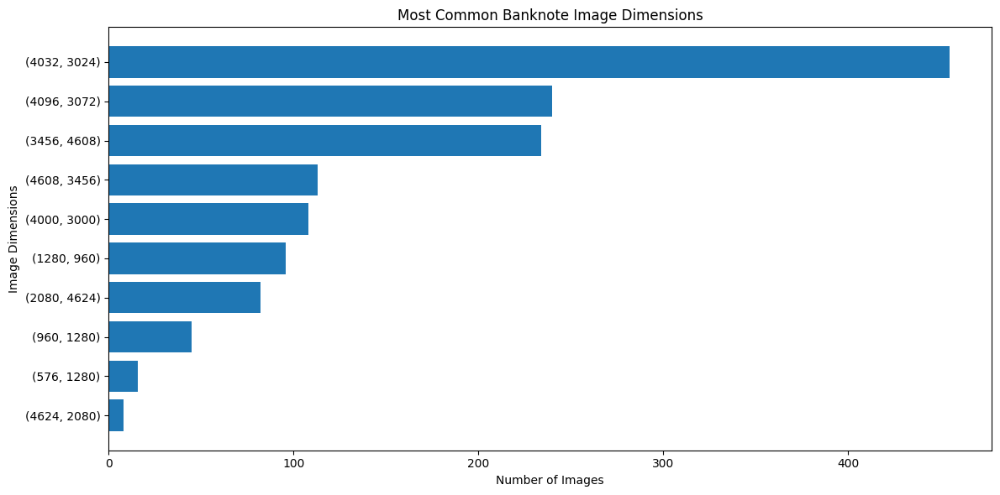

In [ ]:

from collections import Counter
from PIL import Image

dimensions = []

for folder in [genuine_folder, counterfeit_folder]:

    for image_path in folder.iterdir():

        if image_path.suffix.lower() not in [
            ".jpg", ".jpeg", ".png"
        ]:
            continue

        with Image.open(image_path) as img:
            dimensions.append(img.size)

dimension_counts = Counter(dimensions)

top_dimensions = dimension_counts.most_common(10)

sizes = [str(size) for size, count in top_dimensions]
frequencies = [count for size, count in top_dimensions]

plt.figure(figsize=(12, 6))

plt.barh(sizes[::-1], frequencies[::-1])

plt.title("Most Common Banknote Image Dimensions")
plt.xlabel("Number of Images")
plt.ylabel("Image Dimensions")

plt.tight_layout()
plt.show()


# STAGE 2: IMAGE PREPROCESSING VISUALISATION

Investigating how banknote images are transformed into RGB,
structural and texture representations.

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random

from PIL import Image, ImageOps

from src.banknote.preprocessing.transforms import (
    load_banknote_image,
    extract_rgb,
    extract_edges,
    extract_texture
)

print("Preprocessing functions imported successfully!")

Preprocessing functions imported successfully!


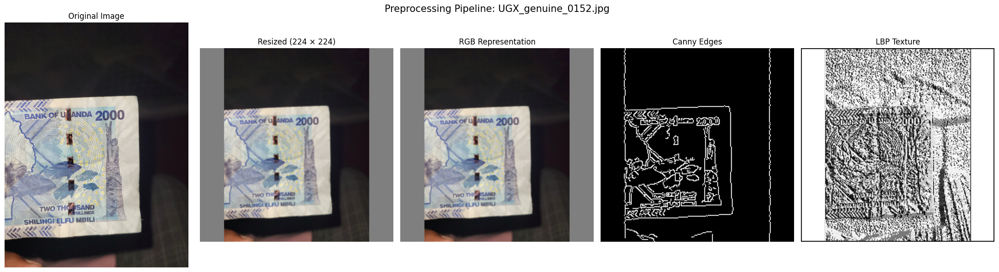

In [ ]:

# Select one random banknote
image_paths = [
    p for p in genuine_folder.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

sample_path = random.choice(image_paths)

# 1. Load original image
original = load_banknote_image(str(sample_path))

# 2. Resize while preserving aspect ratio
resized_pil = ImageOps.pad(
    Image.fromarray(original),
    (224, 224),
    color=(127, 127, 127)
)

resized = np.array(resized_pil)

# 3. Extract RGB
rgb = extract_rgb(resized)

# 4. Extract structural information
edges = extract_edges(resized)

# 5. Extract texture information
texture = extract_texture(resized)

# Display everything
fig, axes = plt.subplots(1, 5, figsize=(22, 6))

images = [
    original,
    resized,
    rgb,
    edges,
    texture
]

titles = [
    "Original Image",
    "Resized (224 × 224)",
    "RGB Representation",
    "Canny Edges",
    "LBP Texture"
]

for ax, img, title in zip(axes, images, titles):

    if img.ndim == 2:
        ax.imshow(img, cmap="gray")
    else:
        ax.imshow(img)

    ax.set_title(title)
    ax.axis("off")

plt.suptitle(
    f"Preprocessing Pipeline: {sample_path.name}",
    fontsize=15
)

plt.tight_layout()
plt.show()


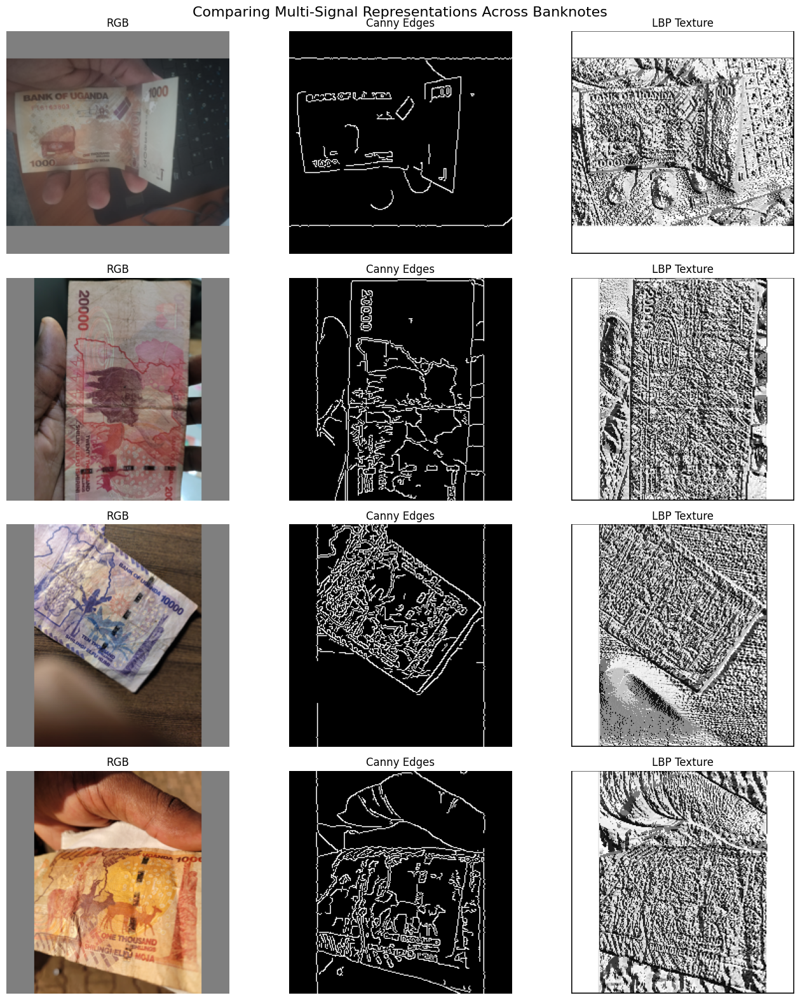

In [ ]:

# Select four genuine banknotes
sample_paths = random.sample(image_paths, 4)

fig, axes = plt.subplots(4, 3, figsize=(14, 16))

for row, path in enumerate(sample_paths):

    original = load_banknote_image(str(path))

    resized = np.array(
        ImageOps.pad(
            Image.fromarray(original),
            (224, 224),
            color=(127, 127, 127)
        )
    )

    rgb = extract_rgb(resized)
    edges = extract_edges(resized)
    texture = extract_texture(resized)

    axes[row, 0].imshow(rgb)
    axes[row, 0].set_title("RGB")

    axes[row, 1].imshow(edges, cmap="gray")
    axes[row, 1].set_title("Canny Edges")

    axes[row, 2].imshow(texture, cmap="gray")
    axes[row, 2].set_title("LBP Texture")

    for ax in axes[row]:
        ax.axis("off")

plt.suptitle(
    "Comparing Multi-Signal Representations Across Banknotes",
    fontsize=16
)

plt.tight_layout()
plt.show()


# STAGE 3: RESNET-18 ARCHITECTURE AND INTERNAL REPRESENTATIONS

Investigating the architecture, residual connections, feature maps
and information flow within the pretrained ResNet-18 model.

In [ ]:

import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np

from src.banknote.models.resnet_baseline import BanknoteResNet18

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

CHECKPOINT_PATH = (
    PROJECT_PATH /
    "models/resnet18_feature_extractor_best.pth"
)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False
)

model = BanknoteResNet18(
    num_classes=2,
    freeze_backbone=True
).to(DEVICE)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("ResNet-18 loaded successfully!")
print("Best checkpoint epoch:", checkpoint["epoch"])
print("Validation loss:", checkpoint["validation_loss"])
print("Validation accuracy:", checkpoint["validation_accuracy"])


ResNet-18 loaded successfully!
Best checkpoint epoch: 8
Validation loss: 0.2724611541935217
Validation accuracy: 0.8691588785046729


In [ ]:

activations = {}

def capture_activation(name):

    def hook(module, inputs, output):
        activations[name] = output.detach()

    return hook


# Register hooks
model.model.layer1.register_forward_hook(
    capture_activation("Layer 1")
)

model.model.layer2.register_forward_hook(
    capture_activation("Layer 2")
)

model.model.layer3.register_forward_hook(
    capture_activation("Layer 3")
)

model.model.layer4.register_forward_hook(
    capture_activation("Layer 4")
)

print("Feature-map hooks registered!")


Feature-map hooks registered!


In [ ]:
from src.banknote.ingest.data_loader import create_data_loaders

# Load the dataset
train_loader, val_loader, test_loader = create_data_loaders()

print("Data loaders created successfully!")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Data loaders created successfully!
Training batches: 125
Validation batches: 27
Testing batches: 27


In [ ]:

# Obtain one validation image
images, labels = next(iter(val_loader))

sample_image = images[0:1].to(DEVICE)

# ImageNet normalisation
mean = torch.tensor(
    [0.485, 0.456, 0.406],
    device=DEVICE
).view(1, 3, 1, 1)

std = torch.tensor(
    [0.229, 0.224, 0.225],
    device=DEVICE
).view(1, 3, 1, 1)

normalised_image = (sample_image - mean) / std

# Forward pass
model.eval()

with torch.no_grad():
    output = model(normalised_image)

print("Original image shape:", sample_image.shape)
print("Model output:", output)

for name, feature in activations.items():
    print(name, ":", feature.shape)


Original image shape: torch.Size([1, 3, 224, 224])
Model output: tensor([[ 0.6586, -1.0300]], device='cuda:0')
Layer 1 : torch.Size([1, 64, 56, 56])
Layer 2 : torch.Size([1, 128, 28, 28])
Layer 3 : torch.Size([1, 256, 14, 14])
Layer 4 : torch.Size([1, 512, 7, 7])


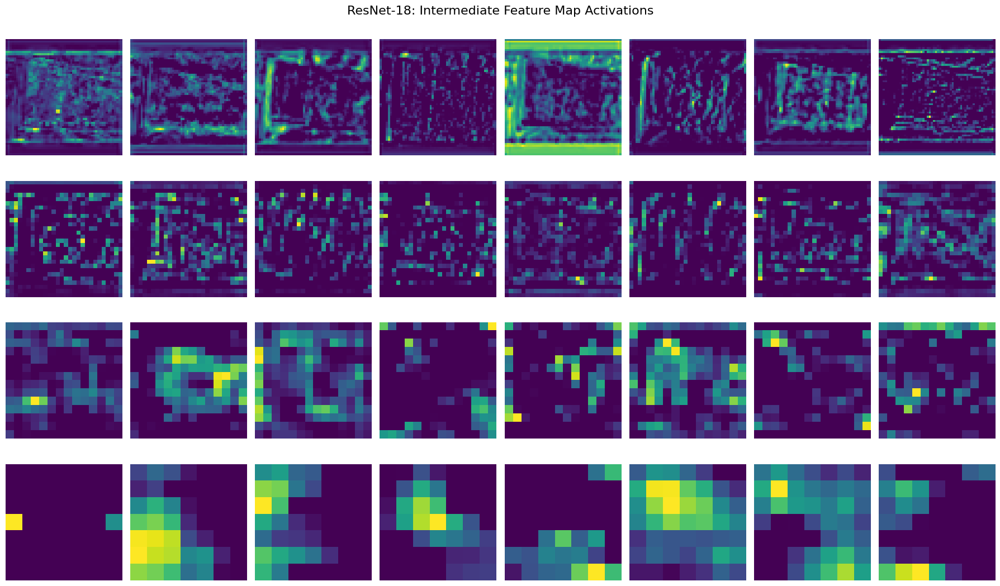

In [ ]:

fig, axes = plt.subplots(4, 8, figsize=(18, 11))

for row, (layer_name, feature_maps) in enumerate(
    activations.items()
):

    for col in range(8):

        feature = feature_maps[0, col].cpu().numpy()

        axes[row, col].imshow(
            feature,
            cmap="viridis"
        )

        axes[row, col].axis("off")

        if col == 0:
            axes[row, col].set_ylabel(
                layer_name,
                fontsize=12
            )

plt.suptitle(
    "ResNet-18: Intermediate Feature Map Activations",
    fontsize=16
)

plt.tight_layout()
plt.show()


# STAGE 4: GRAD-CAM VISUALISATION

Investigating the spatial regions that contribute to
ResNet-18's genuine and counterfeit predictions.

In [ ]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
# Get one validation image
sample_image, sample_label = next(iter(val_loader))

# Select one image
sample_image = sample_image[0:1].to(DEVICE)

# ImageNet normalisation values
mean = torch.tensor(
    [0.485, 0.456, 0.406],
    device=DEVICE
).view(1, 3, 1, 1)

std = torch.tensor(
    [0.229, 0.224, 0.225],
    device=DEVICE
).view(1, 3, 1, 1)

# Prepare original image for display
original_image = (
    sample_image[0]
    .detach()
    .cpu()
    .permute(1, 2, 0)
    .numpy()
)

print("Sample image ready!")
print("Original label:", sample_label[0].item())

Sample image ready!
Original label: 0


In [ ]:
# Select the final convolutional block
target_layer = model.model.layer4[-1]

# Capture feature maps and their gradients
gradcam_data = {}

def gradcam_hook(module, inputs, output):
    gradcam_data["features"] = output
    output.retain_grad()

# Register the new hook
gradcam_handle = target_layer.register_forward_hook(
    gradcam_hook
)

print("Grad-CAM hook successfully registered.")

Grad-CAM hook successfully registered.


In [ ]:
def generate_gradcam(input_image, target_class):

    model.eval()
    model.zero_grad(set_to_none=True)
    gradcam_data.clear()

    # Normalise image
    normalised_image = (
        (input_image - mean) / std
    ).detach().requires_grad_(True)

    with torch.enable_grad():

        # Forward pass
        scores = model(normalised_image)

        # Select target class score
        class_score = scores[0, target_class]

        # Calculate gradients
        class_score.backward()

        # Retrieve activations and gradients
        features = gradcam_data["features"]
        gradients = features.grad

        # Calculate channel importance
        weights = gradients.mean(
            dim=(2, 3),
            keepdim=True
        )

        # Generate heatmap
        cam = (weights * features).sum(dim=1)

        cam = F.relu(cam)

        cam = F.interpolate(
            cam.unsqueeze(1),
            size=(224, 224),
            mode="bilinear",
            align_corners=False
        )

        cam = cam[0, 0].detach().cpu().numpy()

        # Normalise heatmap
        cam = cam / (cam.max() + 1e-8)

    predicted_class = scores.argmax(dim=1).item()

    return cam, predicted_class, scores.detach()

Target: Counterfeit | Prediction: Counterfeit | Scores: [[ 0.65857804 -1.0300475 ]]
Target: Genuine | Prediction: Counterfeit | Scores: [[ 0.65857804 -1.0300475 ]]


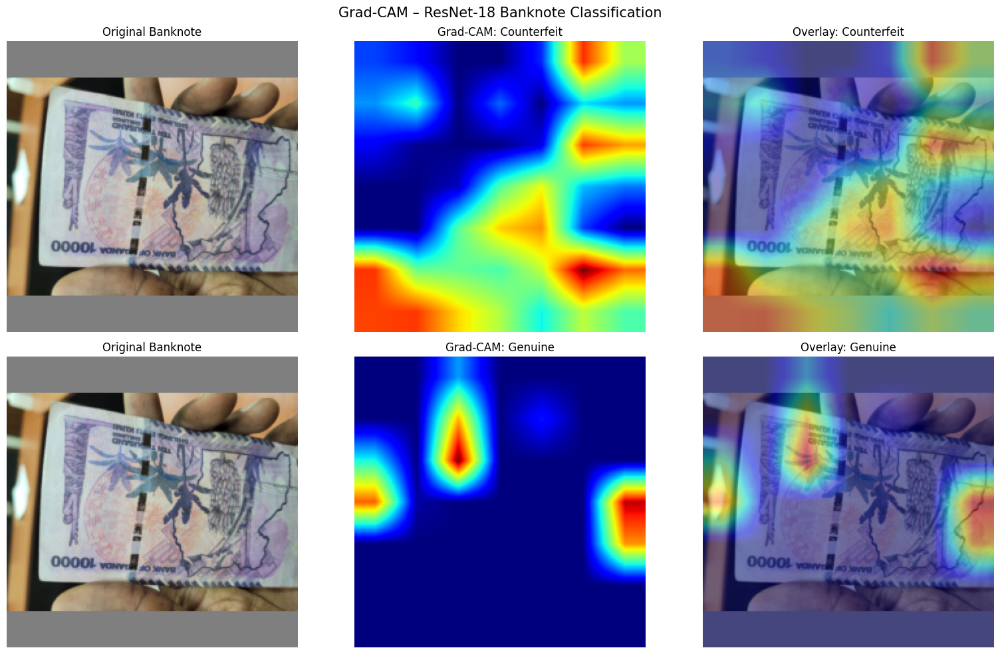

In [ ]:
class_names = {
    0: "Counterfeit",
    1: "Genuine"
}

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for row, target_class in enumerate([0, 1]):

    cam, predicted_class, scores = generate_gradcam(
        sample_image,
        target_class
    )

    # Original image
    axes[row, 0].imshow(original_image)
    axes[row, 0].set_title("Original Banknote")

    # Heatmap
    axes[row, 1].imshow(cam, cmap="jet")
    axes[row, 1].set_title(
        f"Grad-CAM: {class_names[target_class]}"
    )

    # Overlay
    axes[row, 2].imshow(original_image)
    axes[row, 2].imshow(
        cam,
        cmap="jet",
        alpha=0.45
    )
    axes[row, 2].set_title(
        f"Overlay: {class_names[target_class]}"
    )

    for col in range(3):
        axes[row, col].axis("off")

    print(
        f"Target: {class_names[target_class]} | "
        f"Prediction: {class_names[predicted_class]} | "
        f"Scores: {scores.cpu().numpy()}"
    )

plt.suptitle(
    "Grad-CAM – ResNet-18 Banknote Classification",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [ ]:

# CLEAN UP OLD GRAD-CAM HOOKS

target_layer = model.model.layer4[-1]

# Remove the old forward hooks from the target layer
target_layer._forward_hooks.clear()

print("Old Grad-CAM forward hooks cleared.")
print("We can now run normal prediction visualisations.")


Old Grad-CAM forward hooks cleared.
We can now run normal prediction visualisations.


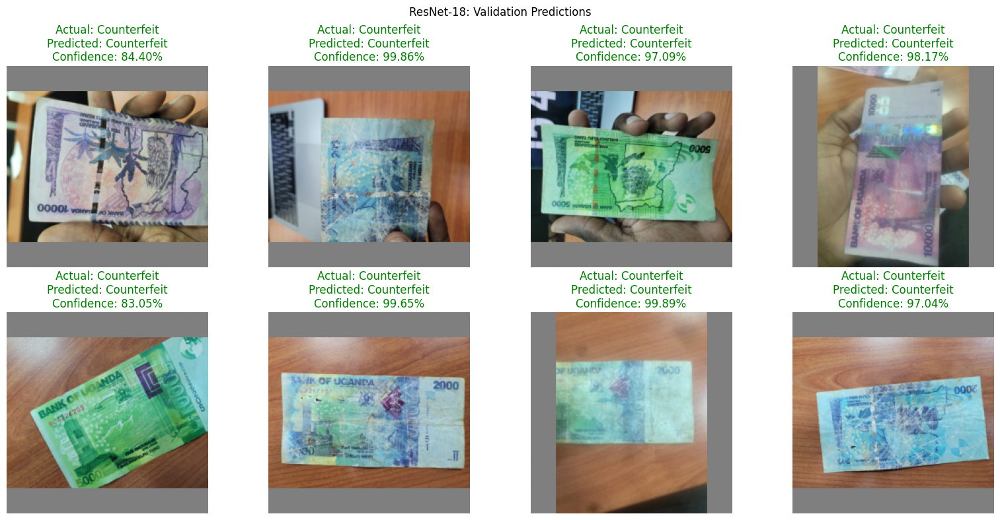

In [ ]:

# INVESTIGATION: PREDICTIONS AND CONFIDENCE

model.eval()

images, labels = next(iter(val_loader))

images = images.to(DEVICE)
labels = labels.to(DEVICE)

normalised_images = (images - mean) / std

with torch.no_grad():

    outputs = model(normalised_images)

    probabilities = torch.softmax(outputs, dim=1)

    predictions = outputs.argmax(dim=1)


class_names = ["Counterfeit", "Genuine"]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for i, ax in enumerate(axes.flat):

    image = images[i].cpu().permute(1, 2, 0).numpy()

    true_label = labels[i].item()
    predicted_label = predictions[i].item()

    confidence = probabilities[i, predicted_label].item()

    ax.imshow(image)

    correct = true_label == predicted_label

    ax.set_title(
        f"Actual: {class_names[true_label]}\n"
        f"Predicted: {class_names[predicted_label]}\n"
        f"Confidence: {confidence:.2%}",
        color="green" if correct else "red"
    )

    ax.axis("off")

plt.suptitle("ResNet-18: Validation Predictions")
plt.tight_layout()
plt.show()


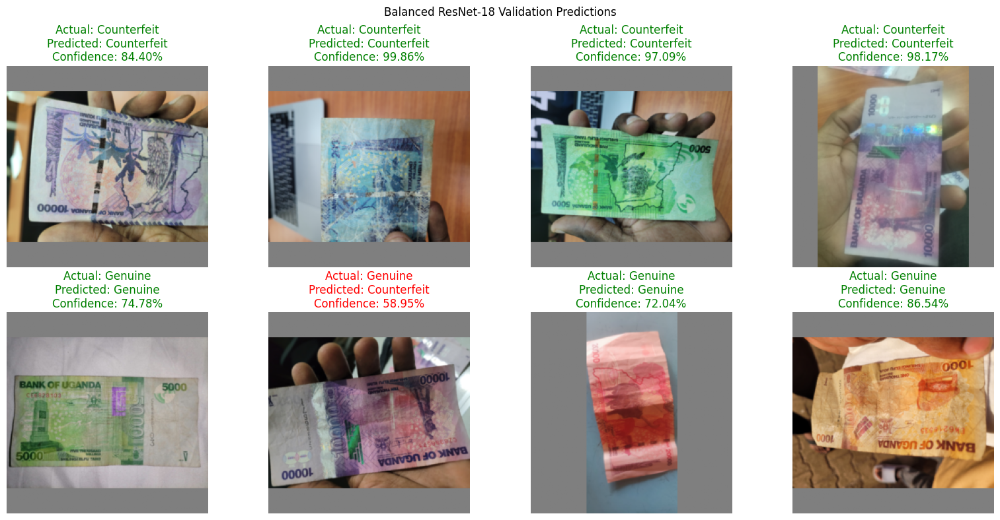

In [ ]:

# BALANCED VALIDATION SAMPLE: 4 GENUINE + 4 COUNTERFEIT

model.eval()

selected_images = {0: [], 1: []}

for batch_images, batch_labels in val_loader:

    for image, label in zip(batch_images, batch_labels):

        class_id = label.item()

        if len(selected_images[class_id]) < 4:
            selected_images[class_id].append(image)

    if all(len(selected_images[c]) == 4 for c in [0, 1]):
        break


fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for row, class_id in enumerate([0, 1]):

    for col, image in enumerate(selected_images[class_id]):

        image_batch = image.unsqueeze(0).to(DEVICE)

        normalised = (image_batch - mean) / std

        with torch.no_grad():
            scores = model(normalised)
            probabilities = torch.softmax(scores, dim=1)

        predicted = scores.argmax(dim=1).item()
        confidence = probabilities[0, predicted].item()

        actual_name = class_names[class_id]
        predicted_name = class_names[predicted]

        correct = predicted == class_id

        axes[row, col].imshow(
            image.permute(1, 2, 0).numpy()
        )

        axes[row, col].set_title(
            f"Actual: {actual_name}\n"
            f"Predicted: {predicted_name}\n"
            f"Confidence: {confidence:.2%}",
            color="green" if correct else "red"
        )

        axes[row, col].axis("off")


plt.suptitle("Balanced ResNet-18 Validation Predictions")
plt.tight_layout()
plt.show()


Validation Performance -Detailed Error Analysis

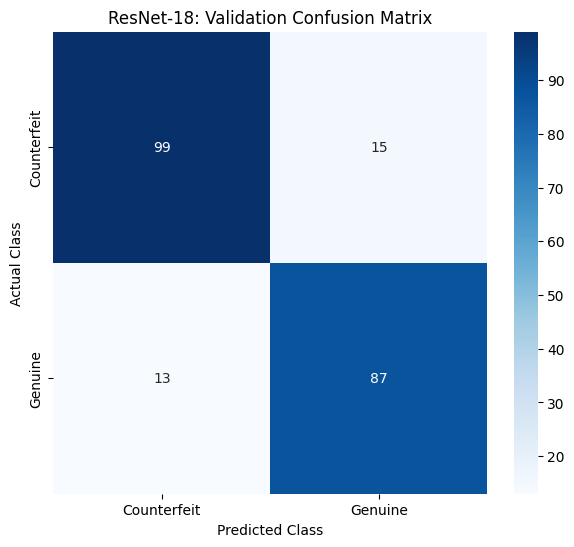


CLASSIFICATION REPORT
              precision    recall  f1-score   support

 Counterfeit     0.8839    0.8684    0.8761       114
     Genuine     0.8529    0.8700    0.8614       100

    accuracy                         0.8692       214
   macro avg     0.8684    0.8692    0.8687       214
weighted avg     0.8694    0.8692    0.8692       214

Balanced Accuracy: 0.8692

Genuine notes classified as counterfeit: 13
Total genuine validation notes: 100


In [ ]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    balanced_accuracy_score
)

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

model.eval()

all_predictions = []
all_labels = []

for images, labels in val_loader:

    images = images.to(DEVICE)
    labels = labels.to(DEVICE)

    normalised_images = (images - mean) / std

    with torch.no_grad():
        outputs = model(normalised_images)
        predictions = outputs.argmax(dim=1)

    all_predictions.extend(predictions.cpu().numpy())
    all_labels.extend(labels.cpu().numpy())


# Confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Counterfeit", "Genuine"],
    yticklabels=["Counterfeit", "Genuine"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("ResNet-18: Validation Confusion Matrix")

plt.show()


# Detailed classification report
print("\nCLASSIFICATION REPORT")
print("=" * 50)

print(
    classification_report(
        all_labels,
        all_predictions,
        labels=[0, 1],
        target_names=["Counterfeit", "Genuine"],
        digits=4,
        zero_division=0
    )
)

print(
    "Balanced Accuracy:",
    round(balanced_accuracy_score(
        all_labels, all_predictions
    ), 4)
)


# Genuine notes incorrectly classified as counterfeit
false_counterfeit = sum(
    actual == 1 and predicted == 0
    for actual, predicted in zip(
        all_labels, all_predictions
    )
)

print(
    "\nGenuine notes classified as counterfeit:",
    false_counterfeit
)

print(
    "Total genuine validation notes:",
    sum(label == 1 for label in all_labels)
)


In [ ]:

# INVESTIGATE ALL MISCLASSIFIED VALIDATION IMAGES

model.eval()

misclassified = []

for images, labels in val_loader:

    images = images.to(DEVICE)
    labels = labels.to(DEVICE)

    normalised_images = (images - mean) / std

    with torch.no_grad():
        outputs = model(normalised_images)

        probabilities = torch.softmax(outputs, dim=1)

        predictions = outputs.argmax(dim=1)

    for i in range(len(labels)):

        actual = labels[i].item()
        predicted = predictions[i].item()

        if actual != predicted:

            misclassified.append({
                "image": images[i].cpu(),
                "actual": actual,
                "predicted": predicted,
                "confidence": probabilities[i, predicted].item()
            })


print("Total misclassified images:", len(misclassified))

# Display the errors
import math

columns = 4
rows = math.ceil(len(misclassified) / columns)

fig, axes = plt.subplots(
    rows, columns,
    figsize=(16, rows * 4)
)

axes = np.array(axes).reshape(-1)

for i, item in enumerate(misclassified):

    image = item["image"].permute(1, 2, 0).numpy()

    actual_name = class_names[item["actual"]]
    predicted_name = class_names[item["predicted"]]

    axes[i].imshow(image)

    axes[i].set_title(
        f"Actual: {actual_name}\n"
        f"Predicted: {predicted_name}\n"
        f"Confidence: {item['confidence']:.2%}",
        color="red"
    )

    axes[i].axis("off")


for i in range(len(misclassified), len(axes)):
    axes[i].axis("off")

plt.suptitle("ResNet-18: Misclassified Validation Images")
plt.tight_layout()
plt.show()


Output hidden; open in https://colab.research.google.com to view.

In [ ]:

# DETAILED ERROR ANALYSIS

import numpy as np
from sklearn.metrics import confusion_matrix

actual = np.array(all_labels)
predicted = np.array(all_predictions)

# Our class mapping:
# 0 = Counterfeit
# 1 = Genuine

counterfeit_as_genuine = np.sum(
    (actual == 0) & (predicted == 1)
)

genuine_as_counterfeit = np.sum(
    (actual == 1) & (predicted == 0)
)

correct = np.sum(actual == predicted)
total = len(actual)

print("=" * 50)
print("RESNET-18 ERROR ANALYSIS")
print("=" * 50)

print("Total validation images:", total)
print("Correct predictions:", correct)
print("Misclassified images:", total - correct)

print("\nCOUNTERFEIT NOTES")
print(
    "Counterfeit classified as genuine:",
    counterfeit_as_genuine
)

print("\nGENUINE NOTES")
print(
    "Genuine classified as counterfeit:",
    genuine_as_counterfeit
)

print("\nERROR RATES")

counterfeit_total = np.sum(actual == 0)
genuine_total = np.sum(actual == 1)

print(
    "Counterfeit false acceptance rate:",
    f"{counterfeit_as_genuine / counterfeit_total * 100:.2f}%"
)

print(
    "Genuine false rejection rate:",
    f"{genuine_as_counterfeit / genuine_total * 100:.2f}%"
)

print("\nCONFUSION MATRIX")
print(confusion_matrix(actual, predicted, labels=[0, 1]))


RESNET-18 ERROR ANALYSIS
Total validation images: 214
Correct predictions: 186
Misclassified images: 28

COUNTERFEIT NOTES
Counterfeit classified as genuine: 15

GENUINE NOTES
Genuine classified as counterfeit: 13

ERROR RATES
Counterfeit false acceptance rate: 13.16%
Genuine false rejection rate: 13.00%

CONFUSION MATRIX
[[99 15]
 [13 87]]


ResNet-18: Model Evaluation
Evaluation of classification performance using accuracy, precision, recall, F1-score, balanced accuracy, ROC-AUC and confusion matrix.

In [ ]:

# ==========================================
# RESNET-18: EVALUATION METRICS
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    matthews_corrcoef
)

# Convert predictions and labels into arrays
y_true = np.array(all_labels)
y_pred = np.array(all_predictions)

# Calculate metrics for the GENUINE class (class 1)
accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred, pos_label=1, zero_division=0
)

recall = recall_score(
    y_true, y_pred, pos_label=1, zero_division=0
)

f1 = f1_score(
    y_true, y_pred, pos_label=1, zero_division=0
)

balanced_accuracy = balanced_accuracy_score(
    y_true, y_pred
)

mcc = matthews_corrcoef(y_true, y_pred)


# Print results
print("=" * 55)
print("RESNET-18 EVALUATION METRICS")
print("=" * 55)

print(f"Accuracy:           {accuracy:.4f}")
print(f"Precision:          {precision:.4f}")
print(f"Recall:             {recall:.4f}")
print(f"F1-score:           {f1:.4f}")
print(f"Balanced Accuracy:  {balanced_accuracy:.4f}")
print(f"Matthews Corrcoef:  {mcc:.4f}")


# Detailed report for both classes
print("\nDETAILED CLASSIFICATION REPORT")
print("=" * 55)

print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["Counterfeit", "Genuine"],
        digits=4,
        zero_division=0
    )
)


RESNET-18 EVALUATION METRICS
Accuracy:           0.8692
Precision:          0.8529
Recall:             0.8700
F1-score:           0.8614
Balanced Accuracy:  0.8692
Matthews Corrcoef:  0.7376

DETAILED CLASSIFICATION REPORT
              precision    recall  f1-score   support

 Counterfeit     0.8839    0.8684    0.8761       114
     Genuine     0.8529    0.8700    0.8614       100

    accuracy                         0.8692       214
   macro avg     0.8684    0.8692    0.8687       214
weighted avg     0.8694    0.8692    0.8692       214



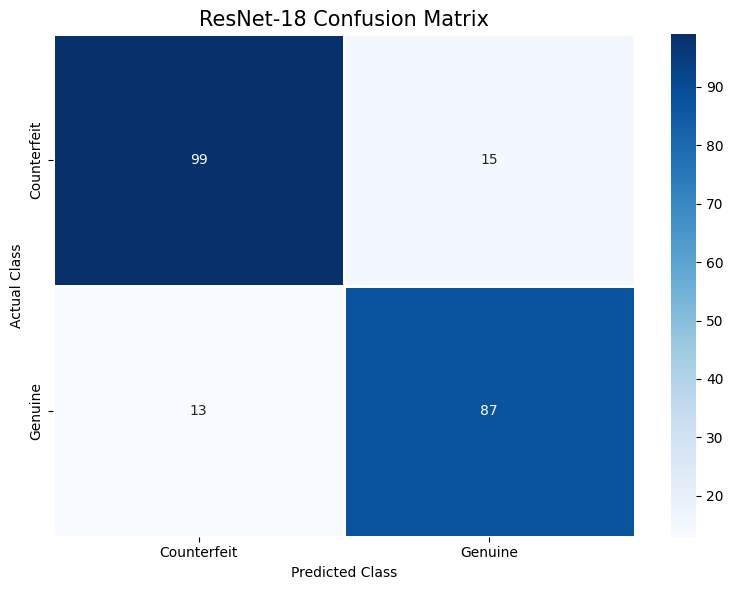

In [ ]:

# ==========================================
# CONFUSION MATRIX VISUALISATION
# ==========================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=1,
    xticklabels=["Counterfeit", "Genuine"],
    yticklabels=["Counterfeit", "Genuine"]
)

plt.title("ResNet-18 Confusion Matrix", fontsize=15)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()


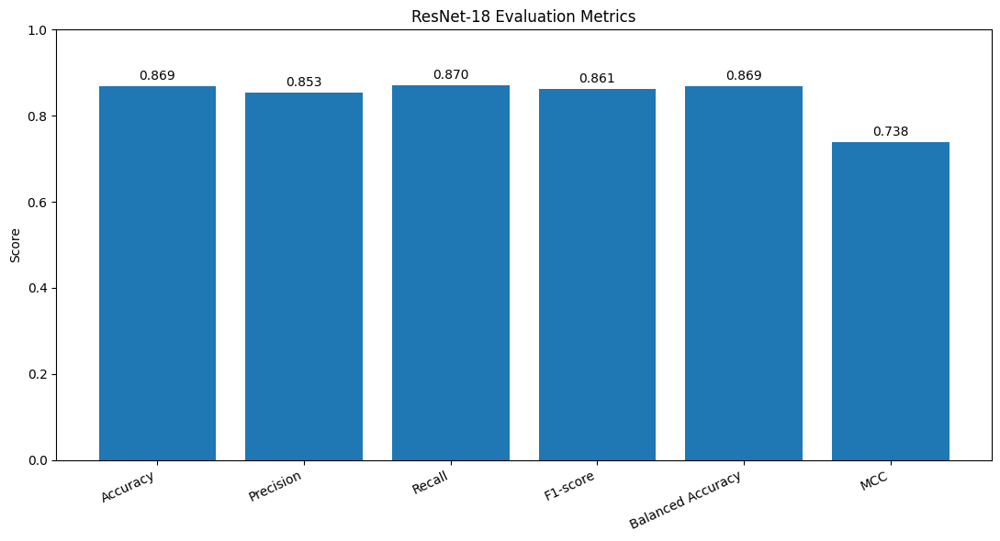

In [ ]:

# ==========================================
# METRICS COMPARISON GRAPH
# ==========================================

metric_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "Balanced Accuracy",
    "MCC"
]

metric_values = [
    accuracy,
    precision,
    recall,
    f1,
    balanced_accuracy,
    mcc
]

plt.figure(figsize=(11, 6))

bars = plt.bar(
    metric_names,
    metric_values
)

plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("ResNet-18 Evaluation Metrics")

plt.xticks(rotation=25, ha="right")

for bar, value in zip(bars, metric_values):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.015,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()


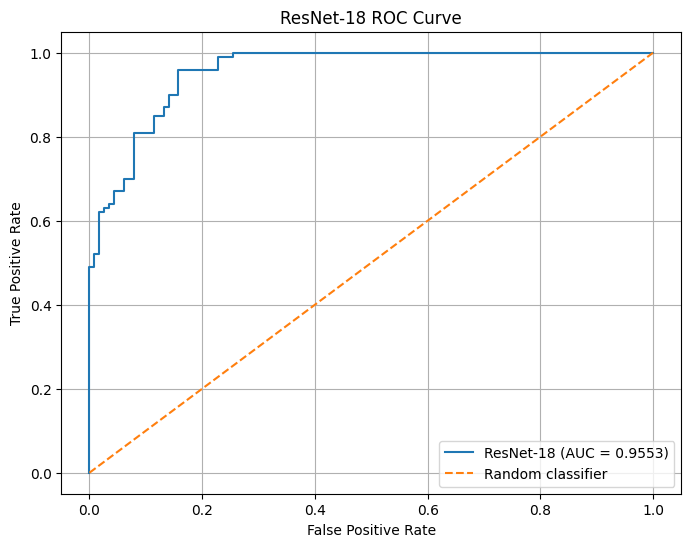

ROC-AUC: 0.9553


In [ ]:

# ==========================================
# ROC CURVE AND AUC
# ==========================================

from sklearn.metrics import roc_curve, auc

model.eval()

all_probabilities = []
roc_labels = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(DEVICE)

        normalised_images = (images - mean) / std

        outputs = model(normalised_images)

        probabilities = torch.softmax(outputs, dim=1)

        # Probability of being genuine (class 1)
        genuine_probabilities = probabilities[:, 1]

        all_probabilities.extend(
            genuine_probabilities.cpu().numpy()
        )

        roc_labels.extend(labels.numpy())


all_probabilities = np.array(all_probabilities)
roc_labels = np.array(roc_labels)

fpr, tpr, thresholds = roc_curve(
    roc_labels,
    all_probabilities,
    pos_label=1
)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"ResNet-18 (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ResNet-18 ROC Curve")

plt.legend()
plt.grid(True)
plt.show()

print("ROC-AUC:", round(roc_auc, 4))



In [ ]:

# ==========================================
# SAVE EVALUATION RESULTS
# ==========================================

from pathlib import Path

results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision_Genuine",
        "Recall_Genuine",
        "F1_Genuine",
        "Balanced_Accuracy",
        "Matthews_Correlation_Coefficient",
        "ROC_AUC"
    ],

    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        balanced_accuracy,
        mcc,
        roc_auc
    ]
})

output_path = (
    PROJECT_PATH /
    "reports/resnet18_evaluation_metrics.csv"
)

results.to_csv(output_path, index=False)

print("Evaluation results saved!")
print(output_path)

display(results)


Evaluation results saved!
/content/drive/MyDrive/ugx-banknote-prototype/reports/resnet18_evaluation_metrics.csv


,Metric,Score
0,Accuracy,0.869159
1,Precision_Genuine,0.852941
2,Recall_Genuine,0.870000
3,F1_Genuine,0.861386
4,Balanced_Accuracy,0.869211
5,Matthews_Correlation_Coefficient,0.737645
6,ROC_AUC,0.955263


In [ ]:
!python -m src.banknote.training.train_resnet18_finetune


RESNET-18 FINE-TUNING
Device: cuda
Epochs: 10
Backbone learning rate: 1e-05
Classifier learning rate: 0.0001

Loaded feature-extraction checkpoint.
Starting checkpoint epoch: 8

Trainable parameters: 10494466

Epoch [1/10]
Train Loss: 0.2622
Train Accuracy: 89.78%
Validation Loss: 0.1848
Validation Accuracy: 92.06%
Epoch Time: 232.44 seconds
Best fine-tuned checkpoint saved!

Epoch [2/10]
Train Loss: 0.1256
Train Accuracy: 96.39%
Validation Loss: 0.1537
Validation Accuracy: 93.93%
Epoch Time: 245.26 seconds
Best fine-tuned checkpoint saved!

Epoch [3/10]
Train Loss: 0.1015
Train Accuracy: 96.49%
Validation Loss: 0.1213
Validation Accuracy: 96.26%
Epoch Time: 252.36 seconds
Best fine-tuned checkpoint saved!

Epoch [4/10]
Train Loss: 0.0659
Train Accuracy: 97.80%
Validation Loss: 0.1126
Validation Accuracy: 95.33%
Epoch Time: 251.37 seconds
Best fine-tuned checkpoint saved!

Epoch [5/10]
Train Loss: 0.0547
Train Accuracy: 98.40%
Validation Loss: 0.0939
Validation Accuracy: 97.20%
Epoch 

ResNet-18 Fine-tuned Model – Final Validation Evaluation

Loaded fine-tuned checkpoint
Selected epoch: 9
Validation loss: 0.07968296127602736
Validation accuracy: 97.66355140186917 %

FINE-TUNED RESNET-18 METRICS
Accuracy:          0.9766
Precision:         0.9897
Recall:            0.9600
F1-score:          0.9746
Balanced Accuracy: 0.9756
MCC:               0.9534
ROC-AUC:           0.9948

DETAILED CLASSIFICATION REPORT
              precision    recall  f1-score   support

 Counterfeit     0.9658    0.9912    0.9784       114
     Genuine     0.9897    0.9600    0.9746       100

    accuracy                         0.9766       214
   macro avg     0.9778    0.9756    0.9765       214
weighted avg     0.9770    0.9766    0.9766       214



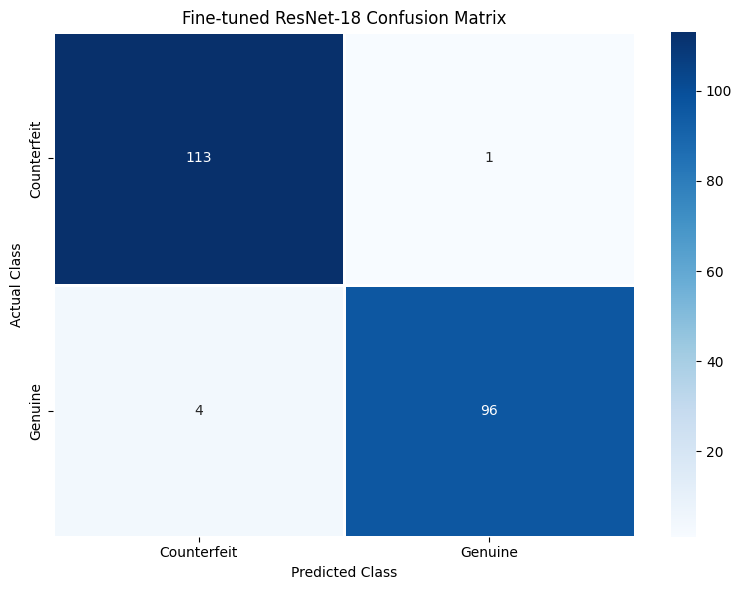


Evaluation results saved successfully!


In [ ]:

# ==========================================
# RESNET-18 FINE-TUNED MODEL EVALUATION
# ==========================================

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

from src.banknote.models.resnet_baseline import BanknoteResNet18


# 1. LOAD BEST FINE-TUNED CHECKPOINT

checkpoint_path = (
    PROJECT_PATH / "models/resnet18_finetuned_best.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=False
)

model = BanknoteResNet18(
    num_classes=2,
    freeze_backbone=True
).to(DEVICE)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Loaded fine-tuned checkpoint")
print("Selected epoch:", checkpoint["epoch"])
print("Validation loss:", checkpoint["validation_loss"])
print(
    "Validation accuracy:",
    checkpoint["validation_accuracy"] * 100,
    "%"
)


# 2. EVALUATE THE VALIDATION SET

y_true_finetuned = []
y_pred_finetuned = []
y_prob_finetuned = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(DEVICE)

        labels = labels.to(DEVICE)

        images = (images - mean) / std

        outputs = model(images)

        probabilities = torch.softmax(outputs, dim=1)

        predictions = outputs.argmax(dim=1)

        y_true_finetuned.extend(
            labels.cpu().numpy()
        )

        y_pred_finetuned.extend(
            predictions.cpu().numpy()
        )

        y_prob_finetuned.extend(
            probabilities[:, 1].cpu().numpy()
        )


y_true_finetuned = np.array(y_true_finetuned)
y_pred_finetuned = np.array(y_pred_finetuned)
y_prob_finetuned = np.array(y_prob_finetuned)


# 3. CALCULATE METRICS

accuracy = accuracy_score(
    y_true_finetuned, y_pred_finetuned
)

precision = precision_score(
    y_true_finetuned,
    y_pred_finetuned,
    pos_label=1,
    zero_division=0
)

recall = recall_score(
    y_true_finetuned,
    y_pred_finetuned,
    pos_label=1,
    zero_division=0
)

f1 = f1_score(
    y_true_finetuned,
    y_pred_finetuned,
    pos_label=1,
    zero_division=0
)

balanced_acc = balanced_accuracy_score(
    y_true_finetuned,
    y_pred_finetuned
)

mcc = matthews_corrcoef(
    y_true_finetuned,
    y_pred_finetuned
)

roc_auc = roc_auc_score(
    y_true_finetuned,
    y_prob_finetuned
)


# 4. PRINT METRICS

print("\nFINE-TUNED RESNET-18 METRICS")
print("=" * 55)

print(f"Accuracy:          {accuracy:.4f}")
print(f"Precision:         {precision:.4f}")
print(f"Recall:            {recall:.4f}")
print(f"F1-score:          {f1:.4f}")
print(f"Balanced Accuracy: {balanced_acc:.4f}")
print(f"MCC:               {mcc:.4f}")
print(f"ROC-AUC:           {roc_auc:.4f}")


# 5. CLASSIFICATION REPORT

print("\nDETAILED CLASSIFICATION REPORT")
print("=" * 55)

print(
    classification_report(
        y_true_finetuned,
        y_pred_finetuned,
        labels=[0, 1],
        target_names=["Counterfeit", "Genuine"],
        digits=4,
        zero_division=0
    )
)


# 6. CONFUSION MATRIX

cm = confusion_matrix(
    y_true_finetuned,
    y_pred_finetuned,
    labels=[0, 1]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=1,
    xticklabels=["Counterfeit", "Genuine"],
    yticklabels=["Counterfeit", "Genuine"]
)

plt.title("Fine-tuned ResNet-18 Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()


# 7. SAVE RESULTS

results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision_Genuine",
        "Recall_Genuine",
        "F1_Genuine",
        "Balanced_Accuracy",
        "MCC",
        "ROC_AUC"
    ],

    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        balanced_acc,
        mcc,
        roc_auc
    ]
})

results.to_csv(
    PROJECT_PATH / "reports/resnet18_finetuned_metrics.csv",
    index=False
)

print("\nEvaluation results saved successfully!")


Multi-Signal Preprocessing – Visual Inspection

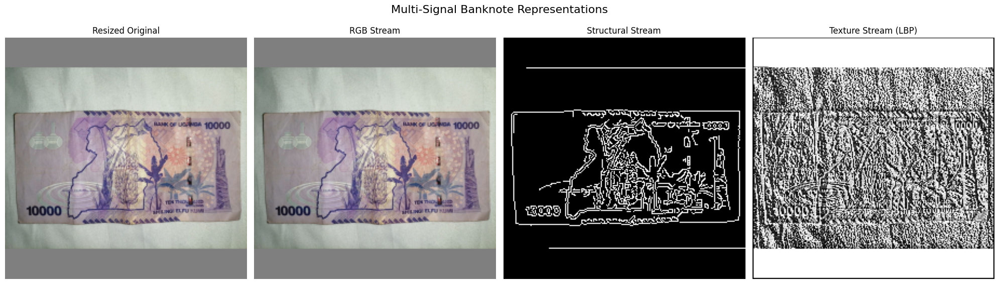

original (224, 224, 3)
rgb (224, 224, 3)
edges (224, 224)
texture (224, 224)


In [ ]:

import matplotlib.pyplot as plt
from pathlib import Path

from src.banknote.preprocessing.prepare_streams import (
    prepare_banknote_streams
)

# Locate dataset
dataset_path = next(
    (PROJECT_PATH / "data/raw").glob(
        "Ugandan banknote*/labelled_ugandan_banknote_dataset_clean"
    )
)

# Select one genuine image
image_folder = dataset_path / "all_images" / "genuine"

image_paths = sorted(image_folder.glob("*.jpg"))

sample_path = image_paths[0]

# Generate representations
streams = prepare_banknote_streams(sample_path)

# Visualise
fig, axes = plt.subplots(1, 4, figsize=(20, 6))

axes[0].imshow(streams["original"])
axes[0].set_title("Resized Original")

axes[1].imshow(streams["rgb"])
axes[1].set_title("RGB Stream")

axes[2].imshow(streams["edges"], cmap="gray")
axes[2].set_title("Structural Stream")

axes[3].imshow(streams["texture"], cmap="gray")
axes[3].set_title("Texture Stream (LBP)")

for ax in axes:
    ax.axis("off")

plt.suptitle(
    "Multi-Signal Banknote Representations",
    fontsize=16
)

plt.tight_layout()
plt.show()

# Display dimensions
for name, representation in streams.items():
    print(name, representation.shape)


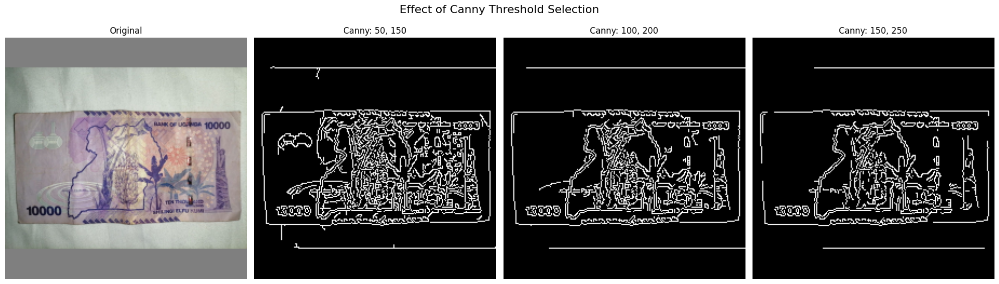

In [ ]:

# ==========================================
# CANNY THRESHOLD COMPARISON
# ==========================================

import cv2
import matplotlib.pyplot as plt

# Use the same original image for every experiment
image = streams["original"]

gray = cv2.cvtColor(
    image,
    cv2.COLOR_RGB2GRAY
)

# Different threshold configurations
thresholds = [
    (50, 150),
    (100, 200),
    (150, 250)
]

fig, axes = plt.subplots(
    1, 4,
    figsize=(20, 6)
)

# Original image
axes[0].imshow(image)
axes[0].set_title("Original")
axes[0].axis("off")

# Compare edge maps
for i, (lower, upper) in enumerate(thresholds):

    edges = cv2.Canny(
        gray,
        threshold1=lower,
        threshold2=upper
    )

    axes[i + 1].imshow(
        edges,
        cmap="gray"
    )

    axes[i + 1].set_title(
        f"Canny: {lower}, {upper}"
    )

    axes[i + 1].axis("off")

plt.suptitle(
    "Effect of Canny Threshold Selection",
    fontsize=16
)

plt.tight_layout()
plt.show()


Minimum LBP value: 0
Maximum LBP value: 255
Mean LBP value: 159.88711734693877
Unique LBP patterns: 256


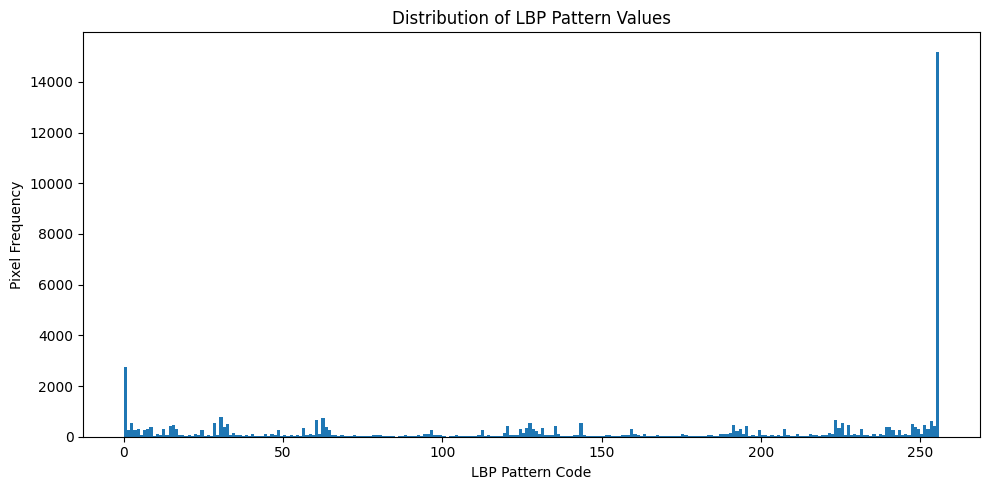

In [ ]:

# ==========================================
# LBP VALUE DISTRIBUTION
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

lbp = streams["texture"]

print("Minimum LBP value:", lbp.min())
print("Maximum LBP value:", lbp.max())
print("Mean LBP value:", lbp.mean())
print("Unique LBP patterns:", len(np.unique(lbp)))

plt.figure(figsize=(10, 5))

plt.hist(
    lbp.ravel(),
    bins=256,
    range=(0, 256)
)

plt.title("Distribution of LBP Pattern Values")
plt.xlabel("LBP Pattern Code")
plt.ylabel("Pixel Frequency")

plt.tight_layout()
plt.show()


Experiment 3A: Canny, LBP and GLCM Analysis

In [ ]:

# Install scikit-image if it is not already available
%pip install -q scikit-image

import cv2
import numpy as np
import matplotlib.pyplot as plt

from skimage.feature import (
    local_binary_pattern,
    graycomatrix,
    graycoprops
)

from src.banknote.preprocessing.prepare_streams import (
    prepare_banknote_streams
)

print("Feature extraction libraries loaded successfully!")


Feature extraction libraries loaded successfully!


Image: UGX_genuine_0001.jpg
Image dimensions: (224, 224, 3)

EDGE DENSITY
50 / 150: 11.65%
100 / 200: 8.97%
150 / 250: 7.56%


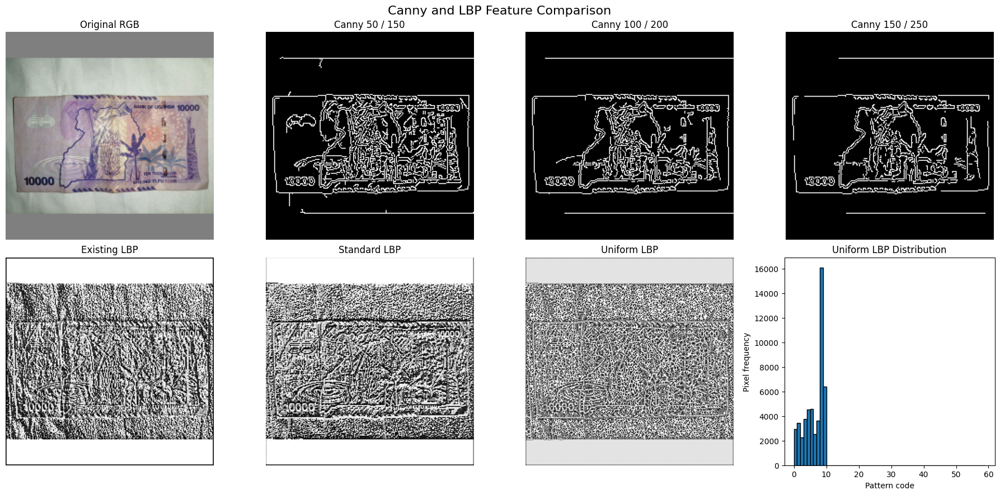

In [ ]:

# ==========================================
# SELECT AND PREPARE A BANKNOTE
# ==========================================

# Reuse the dataset path from our earlier notebook
image_path = sample_path

streams = prepare_banknote_streams(image_path)

rgb = streams["rgb"]

# Convert RGB to grayscale for texture analysis
gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)

print("Image:", image_path.name)
print("Image dimensions:", rgb.shape)


# ==========================================
# CANNY THRESHOLD EXPERIMENT
# ==========================================

canny_50_150 = cv2.Canny(gray, 50, 150)
canny_100_200 = cv2.Canny(gray, 100, 200)
canny_150_250 = cv2.Canny(gray, 150, 250)

edge_maps = {
    "50 / 150": canny_50_150,
    "100 / 200": canny_100_200,
    "150 / 250": canny_150_250
}

print("\nEDGE DENSITY")
print("=" * 35)

for name, edge_map in edge_maps.items():

    density = np.mean(edge_map > 0) * 100

    print(f"{name}: {density:.2f}%")


# ==========================================
# LBP COMPARISON
# ==========================================

radius = 1
neighbours = 8 * radius

# Our existing LBP implementation
existing_lbp = streams["texture"]

# Standard LBP
standard_lbp = local_binary_pattern(
    gray,
    neighbours,
    radius,
    method="default"
)

# Uniform LBP
uniform_lbp = local_binary_pattern(
    gray,
    neighbours,
    radius,
    method="uniform"
)



# ==========================================
# VISUALISE CANNY AND LBP RESULTS
# ==========================================

fig, axes = plt.subplots(2, 4, figsize=(18, 9))

axes[0, 0].imshow(rgb)
axes[0, 0].set_title("Original RGB")

axes[0, 1].imshow(canny_50_150, cmap="gray")
axes[0, 1].set_title("Canny 50 / 150")

axes[0, 2].imshow(canny_100_200, cmap="gray")
axes[0, 2].set_title("Canny 100 / 200")

axes[0, 3].imshow(canny_150_250, cmap="gray")
axes[0, 3].set_title("Canny 150 / 250")

axes[1, 0].imshow(existing_lbp, cmap="gray")
axes[1, 0].set_title("Existing LBP")

axes[1, 1].imshow(standard_lbp, cmap="gray")
axes[1, 1].set_title("Standard LBP")

axes[1, 2].imshow(uniform_lbp, cmap="gray")
axes[1, 2].set_title("Uniform LBP")

axes[1, 3].hist(
    uniform_lbp.ravel(),
    bins=np.arange(60),
    edgecolor="black"
)

axes[1, 3].set_title("Uniform LBP Distribution")
axes[1, 3].set_xlabel("Pattern code")
axes[1, 3].set_ylabel("Pixel frequency")

# Hide axes around the seven image visualisations
for ax in axes.flat:
    if ax is not axes[1, 3]:
        ax.axis("off")

plt.suptitle(
    "Canny and LBP Feature Comparison",
    fontsize=16
)

plt.tight_layout()
plt.show()



GLCM TEXTURE STATISTICS

CONTRAST
Mean:    1.88805
Minimum: 0.91150
Maximum: 3.20405

DISSIMILARITY
Mean:    0.63546
Minimum: 0.40088
Maximum: 0.93522

HOMOGENEITY
Mean:    0.78175
Minimum: 0.70317
Maximum: 0.84323

ENERGY
Mean:    0.31692
Minimum: 0.28707
Maximum: 0.34034

CORRELATION
Mean:    0.81438
Minimum: 0.68545
Maximum: 0.91024

ASM
Mean:    0.10075
Minimum: 0.08241
Maximum: 0.11583


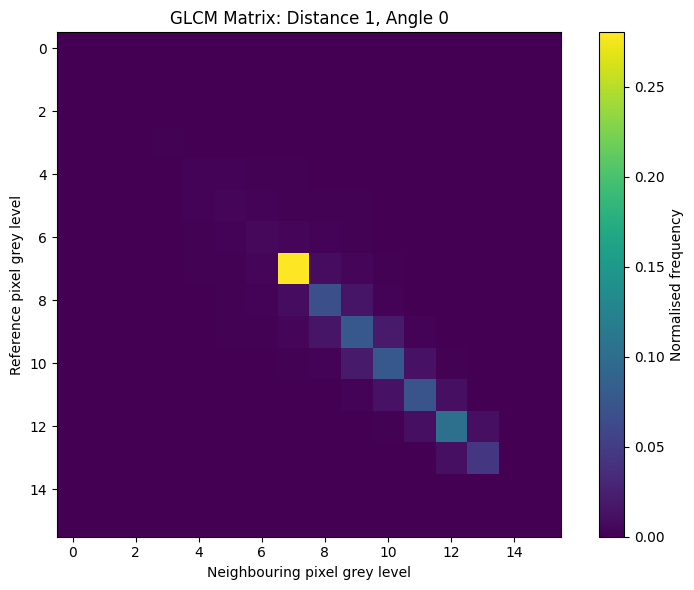

In [ ]:

# ==========================================
# GLCM TEXTURE FEATURE EXTRACTION
# ==========================================

# 1. Quantise grayscale image into 16 levels

levels = 16

quantised_image = (
    gray.astype(np.uint16) * levels // 256
).astype(np.uint8)


# 2. Calculate GLCM

distances = [1, 2, 4]

angles = [
    0,
    np.pi / 4,
    np.pi / 2,
    3 * np.pi / 4
]

glcm = graycomatrix(
    quantised_image,
    distances=distances,
    angles=angles,
    levels=levels,
    symmetric=True,
    normed=True
)


# 3. Extract statistical properties

properties = [
    "contrast",
    "dissimilarity",
    "homogeneity",
    "energy",
    "correlation",
    "ASM"
]

glcm_results = {}

for prop in properties:

    values = graycoprops(glcm, prop)

    glcm_results[prop] = {
        "mean": values.mean(),
        "minimum": values.min(),
        "maximum": values.max()
    }


# 4. Display results

print("GLCM TEXTURE STATISTICS")
print("=" * 55)

for prop, values in glcm_results.items():

    print(f"\n{prop.upper()}")

    print(f"Mean:    {values['mean']:.5f}")
    print(f"Minimum: {values['minimum']:.5f}")
    print(f"Maximum: {values['maximum']:.5f}")


# 5. Visualise one GLCM matrix

plt.figure(figsize=(8, 6))

plt.imshow(
    glcm[:, :, 0, 0],
    cmap="viridis",
    interpolation="nearest"
)

plt.title(
    "GLCM Matrix: Distance 1, Angle 0"
)

plt.xlabel("Neighbouring pixel grey level")
plt.ylabel("Reference pixel grey level")

plt.colorbar(label="Normalised frequency")

plt.tight_layout()
plt.show()


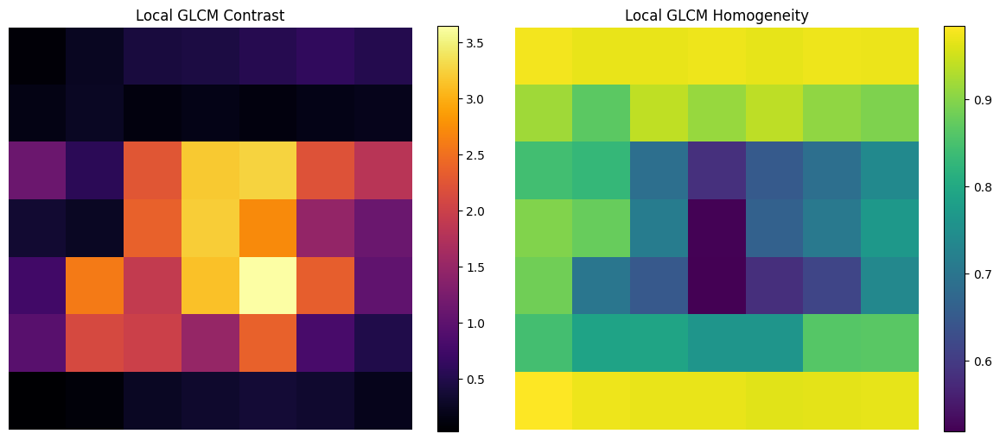

In [ ]:

# ==========================================
# LOCAL GLCM FEATURE MAPS
# ==========================================

patch_size = 32

height, width = quantised_image.shape

contrast_map = np.zeros(
    (height // patch_size, width // patch_size)
)

homogeneity_map = np.zeros_like(contrast_map)


for row in range(contrast_map.shape[0]):

    for col in range(contrast_map.shape[1]):

        y1 = row * patch_size
        y2 = y1 + patch_size

        x1 = col * patch_size
        x2 = x1 + patch_size

        patch = quantised_image[y1:y2, x1:x2]

        patch_glcm = graycomatrix(
            patch,
            distances=[1],
            angles=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4],
            levels=levels,
            symmetric=True,
            normed=True
        )

        contrast_map[row, col] = graycoprops(
            patch_glcm, "contrast"
        ).mean()

        homogeneity_map[row, col] = graycoprops(
            patch_glcm, "homogeneity"
        ).mean()


# Visualise local texture characteristics

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

im1 = axes[0].imshow(
    contrast_map,
    cmap="inferno",
    interpolation="nearest"
)

axes[0].set_title("Local GLCM Contrast")
plt.colorbar(im1, ax=axes[0])

im2 = axes[1].imshow(
    homogeneity_map,
    cmap="viridis",
    interpolation="nearest"
)

axes[1].set_title("Local GLCM Homogeneity")
plt.colorbar(im2, ax=axes[1])

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


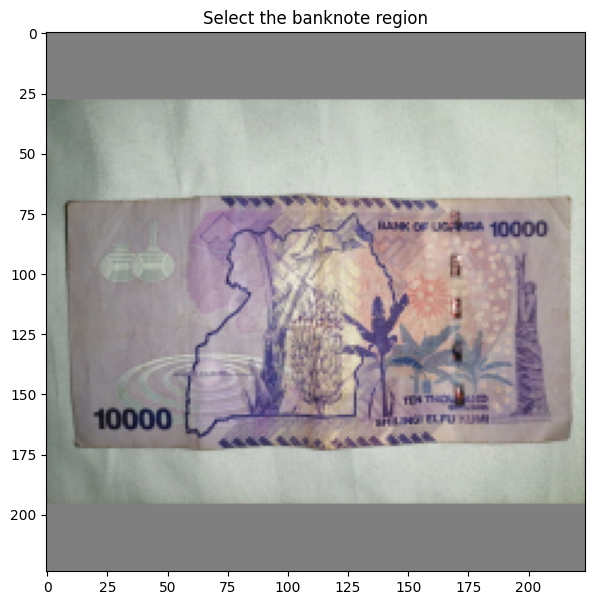

Image shape: (224, 224, 3)
Coordinates use: x = columns, y = rows


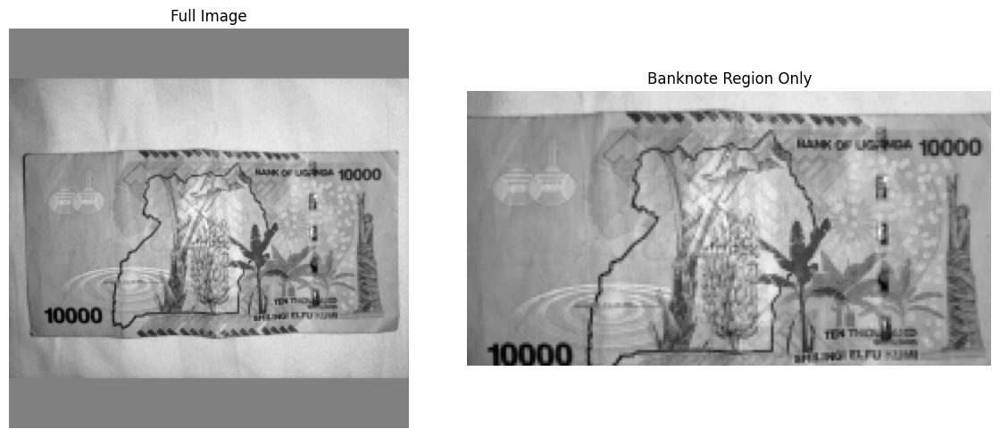


GLCM BACKGROUND INFLUENCE
Feature                   Full Image    Banknote ROI
contrast                    1.88805        3.27811
dissimilarity               0.63546        1.08243
homogeneity                 0.78175        0.63300
energy                      0.31692        0.20781
correlation                 0.81438        0.65527
ASM                         0.10075        0.04359


In [ ]:

# ==========================================
# EXPERIMENT: BACKGROUND INFLUENCE ON GLCM
# ==========================================

import matplotlib.pyplot as plt
import cv2
import numpy as np

from skimage.feature import graycomatrix, graycoprops


# Original resized RGB image
rgb = streams["rgb"]

# Convert to grayscale
gray = cv2.cvtColor(
    rgb,
    cv2.COLOR_RGB2GRAY
)


# Manually select the banknote region.
# These coordinates are initial estimates.
# Adjust them after viewing the displayed image.

plt.figure(figsize=(7, 7))
plt.imshow(rgb)
plt.title("Select the banknote region")
plt.axis("on")
plt.show()

print("Image shape:", rgb.shape)
print("Coordinates use: x = columns, y = rows")


# Initial crop coordinates for this sample.
# Adjust these if the banknote is not fully enclosed.

x1, y1 = 12, 60
x2, y2 = 212, 165

banknote_roi = gray[y1:y2, x1:x2]


# GLCM feature extraction function

def calculate_glcm_features(image):

    quantised = (
        image.astype(np.uint16) * 16 // 256
    ).astype(np.uint8)

    matrix = graycomatrix(
        quantised,
        distances=[1, 2, 4],
        angles=[
            0,
            np.pi / 4,
            np.pi / 2,
            3 * np.pi / 4
        ],
        levels=16,
        symmetric=True,
        normed=True
    )

    features = {}

    for prop in [
        "contrast",
        "dissimilarity",
        "homogeneity",
        "energy",
        "correlation",
        "ASM"
    ]:

        values = graycoprops(matrix, prop)

        features[prop] = values.mean()

    return features


# Calculate features for both images

full_features = calculate_glcm_features(gray)

roi_features = calculate_glcm_features(banknote_roi)


# Display comparison

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(gray, cmap="gray")
axes[0].set_title("Full Image")

axes[1].imshow(banknote_roi, cmap="gray")
axes[1].set_title("Banknote Region Only")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


# Compare measurements

print("\nGLCM BACKGROUND INFLUENCE")
print("=" * 65)

print(f"{'Feature':<20} {'Full Image':>15} {'Banknote ROI':>15}")

for feature in full_features:

    print(
        f"{feature:<20}"
        f"{full_features[feature]:>15.5f}"
        f"{roi_features[feature]:>15.5f}"
    )


In [ ]:

from google.colab import drive
from pathlib import Path
import os
import sys

# Mount Google Drive
drive.mount('/content/drive')

# Locate our research project
PROJECT_PATH = Path(
    "/content/drive/MyDrive/ugx-banknote-prototype"
)

# Confirm the project exists
if not PROJECT_PATH.exists():
    raise FileNotFoundError(
        f"Research project not found: {PROJECT_PATH}"
    )

# Set the project as our working directory
os.chdir(PROJECT_PATH)

# Add project to Python import path
if str(PROJECT_PATH) not in sys.path:
    sys.path.insert(0, str(PROJECT_PATH))

print("PROJECT DIRECTORY:", Path.cwd())
print("Project successfully located!")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PROJECT DIRECTORY: /content/drive/MyDrive/ugx-banknote-prototype
Project successfully located!


In [ ]:
from pathlib import Path

PROJECT_PATH = Path("/content/drive/MyDrive/ugx-banknote-prototype")

DATASET_PATH = (
    PROJECT_PATH
    / "data"
    / "raw"
    / "Ugandan banknote image dataset for genuine and cou"
    / "labelled_ugandan_banknote_dataset_clean"
)

print("Project exists:", PROJECT_PATH.exists())
print("Dataset exists:", DATASET_PATH.exists())
print("Training folder exists:", (DATASET_PATH / "splits" / "train_set").exists())

Project exists: True
Dataset exists: True
Training folder exists: True


In [ ]:

# ==========================================
# GLCM V2: ASPECT-RATIO-PRESERVING PREPROCESSING
# TRAINING SPLIT ONLY
# ==========================================

import cv2
import numpy as np
import pandas as pd

from pathlib import Path
from skimage.feature import graycomatrix, graycoprops

from src.banknote.preprocessing.prepare_streams import (
    resize_preserving_aspect
)

# Dataset location
train_path = DATASET_PATH / "splits" / "train_set"

classes = ["genuine", "counterfeit"]

properties = [
    "contrast",
    "dissimilarity",
    "homogeneity",
    "energy",
    "correlation",
    "ASM"
]

results = []

# Process both classes
for class_name in classes:

    class_folder = train_path / class_name

    image_files = []

    for extension in ["*.jpg", "*.jpeg", "*.png"]:
        image_files.extend(class_folder.glob(extension))

    print(
        f"\nProcessing {class_name}: "
        f"{len(image_files)} images"
    )

    for image_path in image_files:

        image = cv2.imread(str(image_path))

        if image is None:
            continue

        # Convert BGR to RGB
        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        # Preserve aspect ratio and pad to 224 x 224
        image = resize_preserving_aspect(
            image,
            target_size=224
        )

        # Convert to grayscale
        gray = cv2.cvtColor(
            image,
            cv2.COLOR_RGB2GRAY
        )

        # Quantise into 16 grey levels
        quantised = (
            gray.astype(np.uint16) * 16 // 256
        ).astype(np.uint8)

        # Calculate GLCM
        glcm = graycomatrix(
            quantised,
            distances=[1, 2, 4],
            angles=[
                0,
                np.pi / 4,
                np.pi / 2,
                3 * np.pi / 4
            ],
            levels=16,
            symmetric=True,
            normed=True
        )

        row = {
            "filename": image_path.name,
            "class": class_name
        }

        for prop in properties:

            values = graycoprops(glcm, prop)

            row[prop] = values.mean()

        results.append(row)


# Create DataFrame
glcm_df_v2 = pd.DataFrame(results)

# Save separately from the previous experiment
output_path = (
    PROJECT_PATH /
    "reports/glcm_training_features_v2.csv"
)

output_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

glcm_df_v2.to_csv(
    output_path,
    index=False
)

print("\nGLCM V2 COMPLETED")
print("=" * 50)

print("Total images:", len(glcm_df_v2))

print(
    glcm_df_v2["class"].value_counts()
)

print("\nCLASS-WISE FEATURE MEANS")

print(
    glcm_df_v2.groupby("class")[properties]
    .mean()
    .round(5)
)

print("\nSaved to:", output_path)



Processing genuine: 466 images

Processing counterfeit: 532 images

GLCM V2 COMPLETED
Total images: 998
class
counterfeit    532
genuine        466
Name: count, dtype: int64

CLASS-WISE FEATURE MEANS
             contrast  dissimilarity  homogeneity   energy  correlation  \
class                                                                     
counterfeit   1.31835        0.52505      0.80092  0.33546      0.87193   
genuine       1.63185        0.56870      0.79687  0.36652      0.88462   

                 ASM  
class                 
counterfeit  0.11477  
genuine      0.14443  

Saved to: /content/drive/MyDrive/ugx-banknote-prototype/reports/glcm_training_features_v2.csv


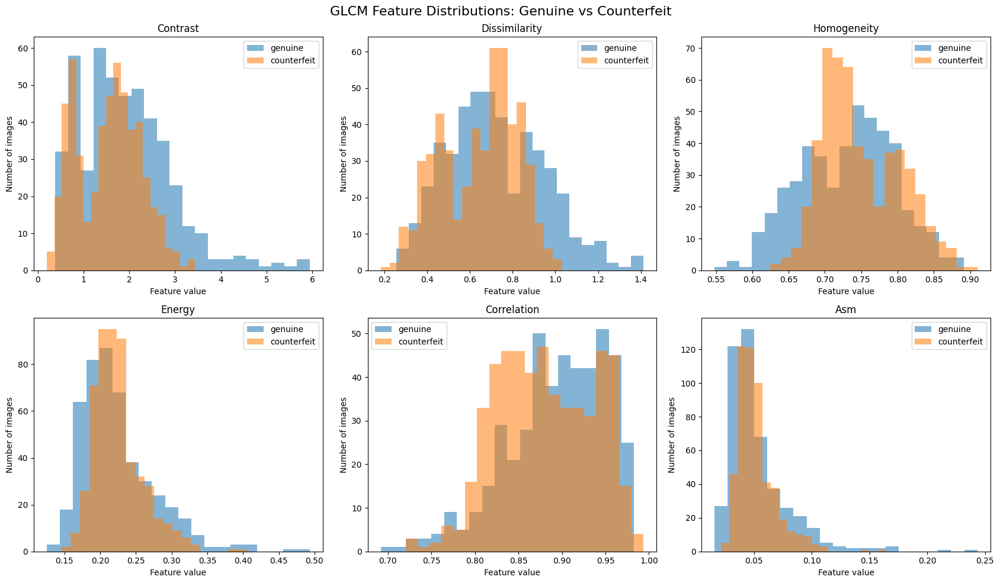

In [ ]:

# ==========================================
# COMPARE GENUINE AND COUNTERFEIT GLCM
# ==========================================

import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    2, 3,
    figsize=(17, 10)
)

for ax, feature in zip(axes.flat, properties):

    for class_name in classes:

        values = glcm_df.loc[
            glcm_df["class"] == class_name,
            feature
        ]

        ax.hist(
            values,
            bins=20,
            alpha=0.55,
            label=class_name
        )

    ax.set_title(feature.capitalize())
    ax.set_xlabel("Feature value")
    ax.set_ylabel("Number of images")
    ax.legend()

plt.suptitle(
    "GLCM Feature Distributions: Genuine vs Counterfeit",
    fontsize=16
)

plt.tight_layout()
plt.show()


In [ ]:

import pandas as pd
from pathlib import Path

# Locate the saved GLCM results
glcm_file = Path("reports/glcm_training_features.csv")

# Check that the file exists
if not glcm_file.exists():
    raise FileNotFoundError(
        f"Could not find {glcm_file.resolve()}. "
        "Check that your project folder is the current working directory."
    )

# Reload the extracted features
glcm_df = pd.read_csv(glcm_file)

print("GLCM dataset successfully reloaded!")
print("Total images:", len(glcm_df))
print("\nColumns:")
print(glcm_df.columns.tolist())

glcm_df.head()


GLCM dataset successfully reloaded!
Total images: 998

Columns:
['filename', 'class', 'contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation', 'ASM']


,filename,class,contrast,dissimilarity,homogeneity,energy,correlation,ASM
0,UGX_genuine_0005.jpg,genuine,3.147598,0.972921,0.668607,0.198788,0.908582,0.039840
1,UGX_genuine_0017.jpg,genuine,1.358151,0.601665,0.767358,0.219951,0.904728,0.048869
2,UGX_genuine_0021.jpg,genuine,1.453038,0.613367,0.762389,0.189129,0.939262,0.036313
3,UGX_genuine_0012.jpg,genuine,1.806814,0.697800,0.735991,0.205168,0.873539,0.042587
4,UGX_genuine_0011.jpg,genuine,2.002507,0.774962,0.714207,0.186233,0.889874,0.035009


In [ ]:

# ==========================================
# STATISTICAL ANALYSIS OF GLCM FEATURES
# ==========================================

import numpy as np
import pandas as pd

from scipy.stats import mannwhitneyu


properties = [
    "contrast",
    "dissimilarity",
    "homogeneity",
    "energy",
    "correlation",
    "ASM"
]

statistical_results = []

for feature in properties:

    genuine = glcm_df.loc[
        glcm_df["class"] == "genuine",
        feature
    ].dropna()

    counterfeit = glcm_df.loc[
        glcm_df["class"] == "counterfeit",
        feature
    ].dropna()

    # Descriptive statistics
    mean_g = genuine.mean()
    mean_c = counterfeit.mean()

    std_g = genuine.std()
    std_c = counterfeit.std()

    # Pooled standard deviation
    pooled_std = np.sqrt(
        (
            (len(genuine) - 1) * std_g**2
            +
            (len(counterfeit) - 1) * std_c**2
        )
        /
        (
            len(genuine) + len(counterfeit) - 2
        )
    )

    # Cohen's d
    cohens_d = (
        (mean_g - mean_c) / pooled_std
        if pooled_std > 0 else np.nan
    )

    # Mann-Whitney U test
    test = mannwhitneyu(
        genuine,
        counterfeit,
        alternative="two-sided"
    )

    statistical_results.append({

        "Feature": feature,

        "Genuine Mean": mean_g,
        "Genuine Std": std_g,

        "Counterfeit Mean": mean_c,
        "Counterfeit Std": std_c,

        "Cohen's d": cohens_d,

        "Mann-Whitney p-value": test.pvalue

    })


results_df = pd.DataFrame(statistical_results)

print("GLCM STATISTICAL COMPARISON")
print("=" * 90)

print(results_df.round(5).to_string(index=False))


GLCM STATISTICAL COMPARISON
      Feature  Genuine Mean  Genuine Std  Counterfeit Mean  Counterfeit Std  Cohen's d  Mann-Whitney p-value
     contrast       1.91538      0.99269           1.54555          0.68338    0.43920               0.00000
dissimilarity       0.72207      0.22577           0.64435          0.17774    0.38553               0.00000
  homogeneity       0.73152      0.06480           0.74999          0.05346   -0.31286               0.00010
       energy       0.22384      0.05204           0.22511          0.03424   -0.02917               0.00263
  correlation       0.89417      0.05644           0.88060          0.05522    0.24315               0.00001
          ASM       0.05322      0.02751           0.05222          0.01695    0.04405               0.00363


Pixels matching padding colour: 25.00%


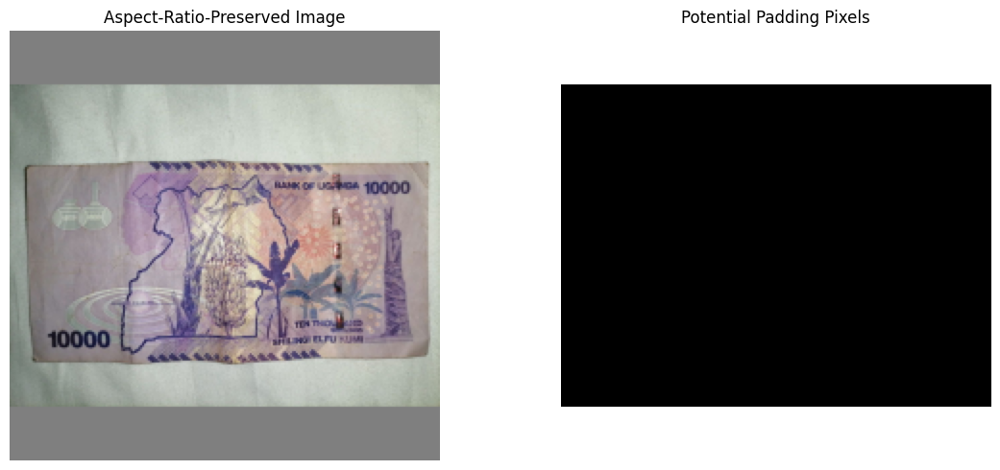

In [ ]:

# ==========================================
# PADDING INFLUENCE DIAGNOSTIC
# ==========================================

import matplotlib.pyplot as plt

sample_path = (
    DATASET_PATH /
    "all_images" /
    "genuine" /
    "UGX_genuine_0001.jpg"
)

image = cv2.imread(str(sample_path))

image = cv2.cvtColor(
    image,
    cv2.COLOR_BGR2RGB
)

processed = resize_preserving_aspect(
    image,
    target_size=224
)

# Identify pixels matching our grey padding
padding_mask = np.all(
    processed == 127,
    axis=2
)

padding_percentage = (
    padding_mask.mean() * 100
)

print(
    f"Pixels matching padding colour: "
    f"{padding_percentage:.2f}%"
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(processed)
axes[0].set_title("Aspect-Ratio-Preserved Image")

axes[1].imshow(
    padding_mask,
    cmap="gray"
)
axes[1].set_title("Potential Padding Pixels")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

# ==========================================
# GLCM V2: CLASS COMPARISON
# ==========================================

properties = [
    "contrast",
    "dissimilarity",
    "homogeneity",
    "energy",
    "correlation",
    "ASM"
]

print("GLCM V2 CLASS MEANS")
print("=" * 50)

print(
    glcm_df_v2.groupby("class")[properties]
    .mean()
    .round(5)
)

print("\nGLCM V2 CLASS STANDARD DEVIATIONS")

print(
    glcm_df_v2.groupby("class")[properties]
    .std()
    .round(5)
)


GLCM V2 CLASS MEANS
             contrast  dissimilarity  homogeneity   energy  correlation  \
class                                                                     
counterfeit   1.31835        0.52505      0.80092  0.33546      0.87193   
genuine       1.63185        0.56870      0.79687  0.36652      0.88462   

                 ASM  
class                 
counterfeit  0.11477  
genuine      0.14443  

GLCM V2 CLASS STANDARD DEVIATIONS
             contrast  dissimilarity  homogeneity   energy  correlation  \
class                                                                     
counterfeit   0.53847        0.13606      0.04053  0.04395      0.05421   
genuine       0.75718        0.17594      0.05319  0.09914      0.04867   

                 ASM  
class                 
counterfeit  0.03681  
genuine      0.08639  


In [ ]:
# Inspect actual pixel values in the processed image

print("Top-left pixel:", processed[0, 0])
print("Top-centre pixel:", processed[0, 112])
print("Centre pixel:", processed[112, 112])
print("Bottom-left pixel:", processed[223, 0])

print("\nMost common RGB values:")
unique_pixels, counts = np.unique(
    processed.reshape(-1, 3),
    axis=0,
    return_counts=True
)

for index in np.argsort(counts)[-10:][::-1]:
    print(unique_pixels[index], ":", counts[index])

Top-left pixel: [127 127 127]
Top-centre pixel: [127 127 127]
Centre pixel: [150 130 136]
Bottom-left pixel: [127 127 127]

Most common RGB values:
[127 127 127] : 12544
[205 213 202] : 92
[200 208 197] : 90
[198 205 197] : 85
[200 207 199] : 85
[202 209 201] : 84
[201 208 200] : 84
[203 211 200] : 83
[203 210 202] : 82
[204 211 203] : 81


Original processed shape: (224, 224, 3)
Unpadded shape: (168, 224, 3)


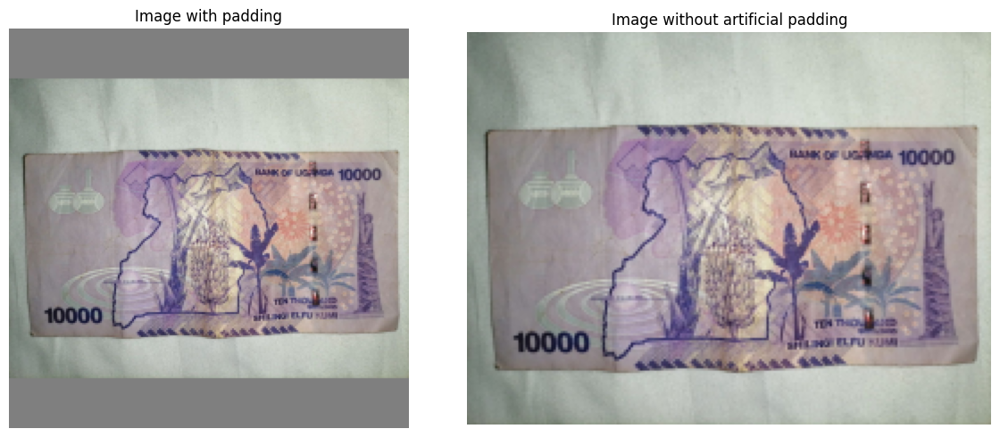

In [ ]:
# GLCM V3: Remove artificial padding only

import cv2
import numpy as np
import matplotlib.pyplot as plt

sample_path = (
    DATASET_PATH / "all_images" / "genuine" /
    "UGX_genuine_0001.jpg"
)

image = cv2.imread(str(sample_path))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

processed = resize_preserving_aspect(image, target_size=224)

# Identify pixels that are not the artificial padding colour
padding_mask = np.all(processed == [127, 127, 127], axis=2)

# Find the rectangular boundary of the original photograph
content_mask = ~padding_mask

ys, xs = np.where(content_mask)

y_min, y_max = ys.min(), ys.max()
x_min, x_max = xs.min(), xs.max()

# Crop away the outer padding
unpadded = processed[
    y_min:y_max + 1,
    x_min:x_max + 1
]

print("Original processed shape:", processed.shape)
print("Unpadded shape:", unpadded.shape)

# Visualise the result
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(processed)
axes[0].set_title("Image with padding")

axes[1].imshow(unpadded)
axes[1].set_title("Image without artificial padding")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Generate GLCM V3 for all 998 training images
Let's first measure the effect of removing artificial padding alone. We should not introduce segmentation at the same time, because then we wouldn't know which change caused any difference in our **measurements**

In [ ]:
# GLCM V3: Aspect-ratio preservation + padding removal

import cv2
import numpy as np
import pandas as pd

from skimage.feature import graycomatrix, graycoprops

results = []

properties = [
    "contrast",
    "dissimilarity",
    "homogeneity",
    "energy",
    "correlation",
    "ASM"
]

train_path = DATASET_PATH / "splits" / "train_set"

for class_name in ["genuine", "counterfeit"]:

    class_folder = train_path / class_name

    image_files = []
    for extension in ["*.jpg", "*.jpeg", "*.png"]:
        image_files.extend(class_folder.glob(extension))

    print(f"Processing {class_name}: {len(image_files)} images")

    for image_path in image_files:

        image = cv2.imread(str(image_path))

        if image is None:
            continue

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # Preserve the original aspect ratio
        processed = resize_preserving_aspect(
            image,
            target_size=224
        )

        # Identify and remove artificial padding
        padding_mask = np.all(
            processed == [127, 127, 127],
            axis=2
        )

        content_mask = ~padding_mask
        ys, xs = np.where(content_mask)

        if len(ys) == 0:
            continue

        y_min, y_max = ys.min(), ys.max()
        x_min, x_max = xs.min(), xs.max()

        unpadded = processed[
            y_min:y_max + 1,
            x_min:x_max + 1
        ]

        # Convert to grayscale
        gray = cv2.cvtColor(
            unpadded,
            cv2.COLOR_RGB2GRAY
        )

        # Quantise to 16 grey levels
        quantised = (
            gray.astype(np.uint16) * 16 // 256
        ).astype(np.uint8)

        glcm = graycomatrix(
            quantised,
            distances=[1, 2, 4],
            angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
            levels=16,
            symmetric=True,
            normed=True
        )

        row = {
            "filename": image_path.name,
            "class": class_name
        }

        for prop in properties:
            row[prop] = graycoprops(
                glcm,
                prop
            ).mean()

        results.append(row)

glcm_df_v3 = pd.DataFrame(results)

output_path = PROJECT_PATH / "reports" / "glcm_training_features_v3.csv"

glcm_df_v3.to_csv(output_path, index=False)

print("\nGLCM V3 COMPLETED")
print("Total images:", len(glcm_df_v3))
print("\nClass counts:")
print(glcm_df_v3["class"].value_counts())

print("\nCLASS-WISE FEATURE MEANS")
print(glcm_df_v3.groupby("class")[properties].mean().round(5))

print("\nCLASS-WISE STANDARD DEVIATIONS")
print(glcm_df_v3.groupby("class")[properties].std().round(5))

print("\nSaved to:", output_path)

Processing genuine: 466 images
Processing counterfeit: 532 images

GLCM V3 COMPLETED
Total images: 998

Class counts:
class
counterfeit    532
genuine        466
Name: count, dtype: int64

CLASS-WISE FEATURE MEANS
             contrast  dissimilarity  homogeneity   energy  correlation  \
class                                                                     
counterfeit   1.65349        0.67112      0.74274  0.22314      0.87179   
genuine       2.09405        0.76700      0.71865  0.22031      0.88300   

                ASM  
class                
counterfeit  0.0513  
genuine      0.0517  

CLASS-WISE STANDARD DEVIATIONS
             contrast  dissimilarity  homogeneity   energy  correlation  \
class                                                                     
counterfeit   0.72115        0.17836      0.05168  0.03341      0.05762   
genuine       1.07043        0.23350      0.06559  0.05265      0.06105   

                 ASM  
class                 
counterfeit  0.016

In [ ]:

import pandas as pd
import numpy as np
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

# Load both experiments
v2 = pd.read_csv(
    PROJECT_PATH / "reports" / "glcm_training_features_v2.csv"
)

v3 = pd.read_csv(
    PROJECT_PATH / "reports" / "glcm_training_features_v3.csv"
)

properties = [
    "contrast",
    "dissimilarity",
    "homogeneity",
    "energy",
    "correlation",
    "ASM"
]

def analyse_glcm(df, version):

    results = []

    genuine = df[df["class"] == "genuine"]
    counterfeit = df[df["class"] == "counterfeit"]

    for feature in properties:

        g = genuine[feature].dropna()
        c = counterfeit[feature].dropna()

        pooled_std = np.sqrt(
            (
                (len(g) - 1) * g.var(ddof=1)
                + (len(c) - 1) * c.var(ddof=1)
            ) / (len(g) + len(c) - 2)
        )

        cohens_d = (g.mean() - c.mean()) / pooled_std

        test = mannwhitneyu(
            g,
            c,
            alternative="two-sided"
        )

        results.append({
            "version": version,
            "feature": feature,
            "cohens_d": cohens_d,
            "p_value": test.pvalue
        })

    result_df = pd.DataFrame(results)

    result_df["holm_p"] = multipletests(
        result_df["p_value"],
        method="holm"
    )[1]

    return result_df

comparison = pd.concat([
    analyse_glcm(v2, "V2"),
    analyse_glcm(v3, "V3")
], ignore_index=True)

print(comparison.round(5).to_string(index=False))


version       feature  cohens_d  p_value  holm_p
     V2      contrast   0.48245  0.00000 0.00000
     V2 dissimilarity   0.27988  0.00200 0.00801
     V2   homogeneity  -0.08629  0.88997 1.00000
     V2        energy   0.41438  0.37878 1.00000
     V2   correlation   0.24555  0.00011 0.00057
     V2           ASM   0.45725  0.39631 1.00000
     V3      contrast   0.48884  0.00000 0.00000
     V3 dissimilarity   0.46556  0.00000 0.00000
     V3   homogeneity  -0.41120  0.00000 0.00000
     V3        energy  -0.06527  0.00004 0.00013
     V3   correlation   0.18928  0.00040 0.00040
     V3           ASM   0.01765  0.00006 0.00013


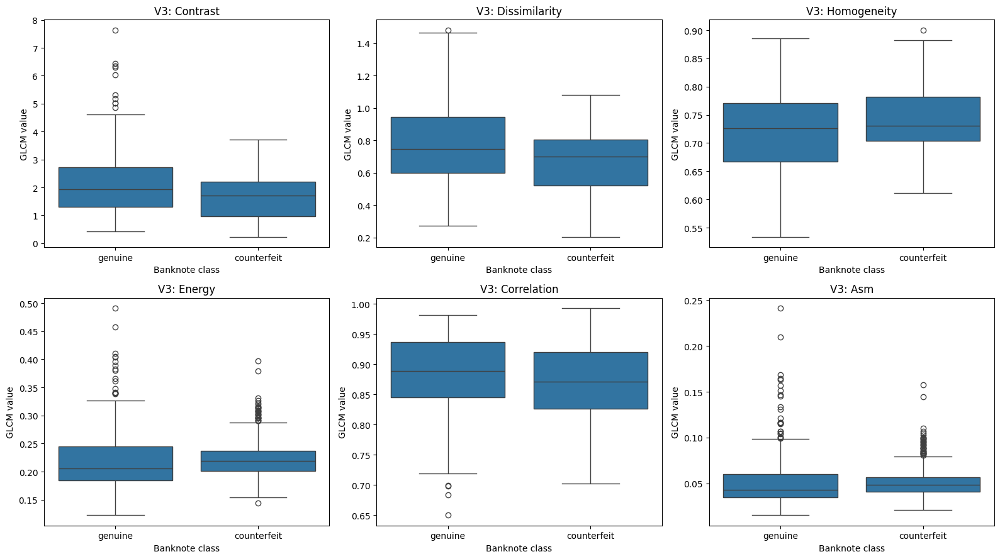

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

features = [
    "contrast",
    "dissimilarity",
    "homogeneity",
    "energy",
    "correlation",
    "ASM"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, feature in zip(axes.flatten(), features):

    sns.boxplot(
        data=v3,
        x="class",
        y=feature,
        ax=ax
    )

    ax.set_title(f"V3: {feature.capitalize()}")
    ax.set_xlabel("Banknote class")
    ax.set_ylabel("GLCM value")

plt.tight_layout()
plt.show()


In [ ]:
print(
    comparison.to_string(
        index=False,
        formatters={
            "p_value": lambda x: f"{x:.3e}",
            "holm_p": lambda x: f"{x:.3e}"
        }
    )
)

version       feature  cohens_d   p_value    holm_p
     V2      contrast  0.482449 8.200e-10 4.920e-09
     V2 dissimilarity  0.279883 2.002e-03 8.008e-03
     V2   homogeneity -0.086292 8.900e-01 1.000e+00
     V2        energy  0.414383 3.788e-01 1.000e+00
     V2   correlation  0.245549 1.139e-04 5.697e-04
     V2           ASM  0.457248 3.963e-01 1.000e+00
     V3      contrast  0.488838 1.994e-10 1.196e-09
     V3 dissimilarity  0.465558 3.003e-09 1.501e-08
     V3   homogeneity -0.411196 6.134e-08 2.454e-07
     V3        energy -0.065272 4.294e-05 1.288e-04
     V3   correlation  0.189275 3.950e-04 3.950e-04
     V3           ASM  0.017655 5.703e-05 1.288e-04


# banknote **segmentation**


In [ ]:

import cv2
import random
import matplotlib.pyplot as plt
from pathlib import Path

train_path = DATASET_PATH / "splits" / "train_set"

random.seed(42)

sample_images = []

for class_name in ["genuine", "counterfeit"]:

    class_folder = train_path / class_name

    files = []
    for extension in ["*.jpg", "*.jpeg", "*.png"]:
        files.extend(class_folder.glob(extension))

    selected = random.sample(files, 3)

    for image_path in selected:
        sample_images.append({
            "path": image_path,
            "class": class_name
        })

for item in sample_images:
    print(item["class"], ":", item["path"].name)


genuine : UGX_genuine_0464.jpg
genuine : UGX_genuine_0087.jpg
genuine : UGX_genuine_0033.jpg
counterfeit : UGX_counterfeit_0396.jpg
counterfeit : UGX_counterfeit_0356.jpg
counterfeit : UGX_counterfeit_0334.jpg


In [ ]:

import numpy as np

fig, axes = plt.subplots(3, 2, figsize=(15, 17))

for index, item in enumerate(sample_images):

    image = cv2.imread(str(item["path"]))
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # 1. Convert to grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # 2. Reduce image noise
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    # 3. Detect edges
    edges = cv2.Canny(blurred, 50, 150)

    # 4. Connect nearby edge fragments
    kernel = np.ones((5, 5), np.uint8)

    closed = cv2.morphologyEx(
        edges,
        cv2.MORPH_CLOSE,
        kernel,
        iterations=2
    )

    # 5. Find external contours
    contours, _ = cv2.findContours(
        closed,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    # 6. Draw the largest candidate contours
    candidates = sorted(
        contours,
        key=cv2.contourArea,
        reverse=True
    )[:5]

    result = image_rgb.copy()

    image_area = image.shape[0] * image.shape[1]

    for contour in candidates:

        area_ratio = cv2.contourArea(contour) / image_area

        # Ignore tiny contours and near-full-image contours
        if 0.05 < area_ratio < 0.95:

            cv2.drawContours(
                result,
                [contour],
                -1,
                (255, 0, 0),
                8
            )

    row = index // 2
    col = index % 2

    axes[row, col].imshow(result)
    axes[row, col].set_title(
        f'{item["class"].capitalize()} — {item["path"].name}'
    )
    axes[row, col].axis("off")

plt.tight_layout()
plt.show()


Output hidden; open in https://colab.research.google.com to view.

# Test GrabCut on our six images

In [ ]:

import random
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Re-establish the training dataset location
train_path = DATASET_PATH / "splits" / "train_set"

# Recreate our six representative samples
random.seed(42)

sample_images = []

for class_name in ["genuine", "counterfeit"]:

    class_folder = train_path / class_name

    files = []
    for extension in ["*.jpg", "*.jpeg", "*.png"]:
        files.extend(class_folder.glob(extension))

    selected = random.sample(files, 3)

    for image_path in selected:
        sample_images.append({
            "path": image_path,
            "class": class_name
        })

print("Samples restored:", len(sample_images))

for item in sample_images:
    print(item["class"], ":", item["path"].name)


Samples restored: 6
genuine : UGX_genuine_0464.jpg
genuine : UGX_genuine_0087.jpg
genuine : UGX_genuine_0033.jpg
counterfeit : UGX_counterfeit_0396.jpg
counterfeit : UGX_counterfeit_0356.jpg
counterfeit : UGX_counterfeit_0334.jpg


KeyboardInterrupt: 

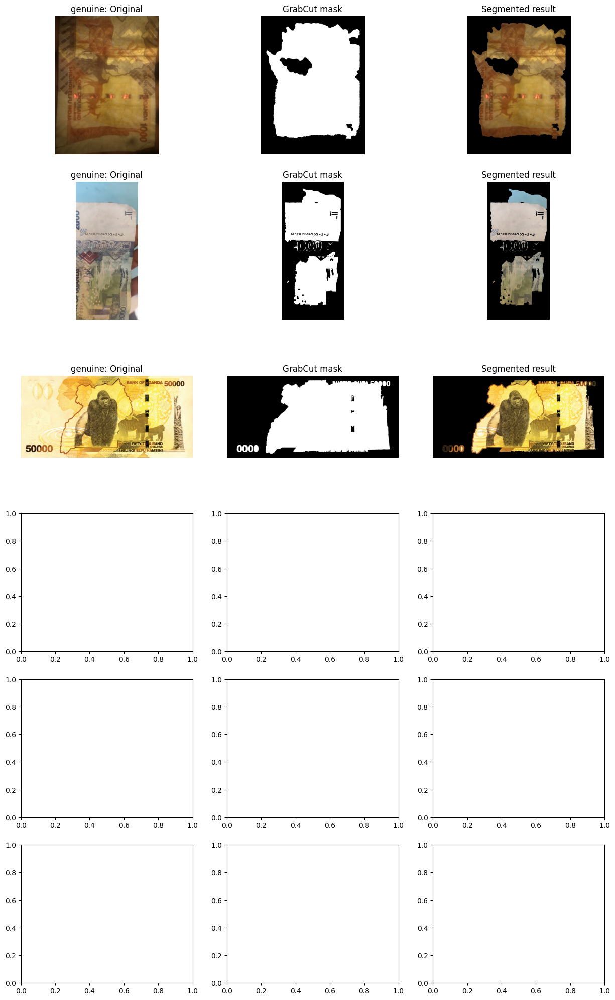

In [ ]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(6, 3, figsize=(15, 25))

for index, item in enumerate(sample_images):

    image = cv2.imread(str(item["path"]))

    if image is None:
        continue

    height, width = image.shape[:2]

    # Start with a rectangle covering most of the image.
    # The rectangle is only an initial foreground estimate.
    margin_x = int(width * 0.05)
    margin_y = int(height * 0.05)

    rect = (
        margin_x,
        margin_y,
        width - 2 * margin_x,
        height - 2 * margin_y
    )

    mask = np.zeros(
        (height, width),
        dtype=np.uint8
    )

    background_model = np.zeros((1, 65), np.float64)
    foreground_model = np.zeros((1, 65), np.float64)

    cv2.grabCut(
        image,
        mask,
        rect,
        background_model,
        foreground_model,
        5,
        cv2.GC_INIT_WITH_RECT
    )

    # Foreground includes definite and probable foreground
    foreground_mask = np.where(
        (mask == cv2.GC_FGD) |
        (mask == cv2.GC_PR_FGD),
        1,
        0
    ).astype(np.uint8)

    segmented = image * foreground_mask[:, :, np.newaxis]

    axes[index, 0].imshow(
        cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    )
    axes[index, 0].set_title(
        f'{item["class"]}: Original'
    )

    axes[index, 1].imshow(
        foreground_mask,
        cmap="gray"
    )
    axes[index, 1].set_title("GrabCut mask")

    axes[index, 2].imshow(
        cv2.cvtColor(segmented, cv2.COLOR_BGR2RGB)
    )
    axes[index, 2].set_title("Segmented result")

    for ax in axes[index]:
        ax.axis("off")

plt.tight_layout()
plt.show()

## verify the three streams

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project located successfully.
Dataset located successfully.
Preprocessing module imported successfully.

Selected image: UGX_genuine_0002.jpg
Image loaded successfully.
Original dimensions: (3456, 4608, 3)

THREE-STREAM OUTPUT

ORIGINAL
Shape: (224, 224, 3)
Data type: uint8
Minimum: 10
Maximum: 253

RGB
Shape: (224, 224, 3)
Data type: uint8
Minimum: 10
Maximum: 253

EDGES
Shape: (224, 224)
Data type: uint8
Minimum: 0
Maximum: 255

TEXTURE
Shape: (224, 224)
Data type: uint8
Minimum: 0
Maximum: 255

SUCCESS: All three streams are spatially aligned.


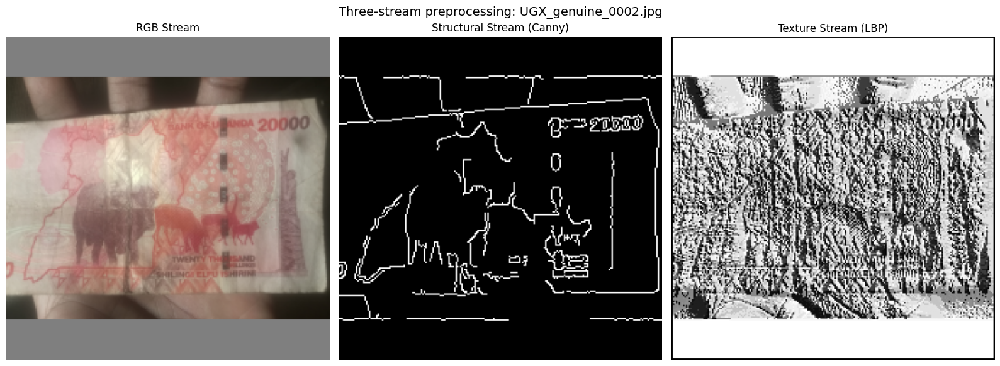


THREE-STREAM PREPROCESSING TEST COMPLETED.


In [ ]:

# ============================================================
# THREE-STREAM BANKNOTE PREPROCESSING
# RGB + STRUCTURAL (EDGES) + TEXTURE (LBP)
# ============================================================

# 1. IMPORT LIBRARIES
import os
import sys
import cv2
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from google.colab import drive

# 2. MOUNT GOOGLE DRIVE
drive.mount("/content/drive")

# 3. LOCATE RESEARCH PROJECT
PROJECT_PATH = Path(
    "/content/drive/MyDrive/ugx-banknote-prototype"
)

if not PROJECT_PATH.exists():
    raise FileNotFoundError(
        f"Research project not found: {PROJECT_PATH}"
    )

os.chdir(PROJECT_PATH)

if str(PROJECT_PATH) not in sys.path:
    sys.path.insert(0, str(PROJECT_PATH))

# 4. LOCATE DATASET
DATASET_PATH = (
    PROJECT_PATH
    / "data"
    / "raw"
    / "Ugandan banknote image dataset for genuine and cou"
    / "labelled_ugandan_banknote_dataset_clean"
)

if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f"Dataset folder not found: {DATASET_PATH}"
    )

# 5. IMPORT EXISTING PREPROCESSING FUNCTIONS
from src.banknote.preprocessing.prepare_streams import (
    prepare_banknote_streams
)

print("Project located successfully.")
print("Dataset located successfully.")
print("Preprocessing module imported successfully.")

# 6. AUTOMATICALLY SELECT AN EXISTING IMAGE
genuine_folder = (
    DATASET_PATH / "splits" / "train_set" / "genuine"
)

image_files = sorted(genuine_folder.glob("*.jpg"))

if not image_files:
    image_files = sorted(genuine_folder.glob("*.jpeg"))

if not image_files:
    image_files = sorted(genuine_folder.glob("*.png"))

if not image_files:
    raise FileNotFoundError(
        "No genuine training images were found."
    )

sample_path = image_files[0]

print("\nSelected image:", sample_path.name)

# 7. VERIFY IMAGE LOADING
test_image = cv2.imread(str(sample_path))

if test_image is None:
    raise ValueError(
        f"OpenCV could not read: {sample_path}"
    )

print("Image loaded successfully.")
print("Original dimensions:", test_image.shape)

# 8. GENERATE THREE REPRESENTATIONS
streams = prepare_banknote_streams(
    str(sample_path),
    target_size=224
)

# 9. DISPLAY STREAM INFORMATION
print("\nTHREE-STREAM OUTPUT")
print("=" * 50)

for name, array in streams.items():

    if isinstance(array, np.ndarray):

        print(f"\n{name.upper()}")
        print("Shape:", array.shape)
        print("Data type:", array.dtype)
        print("Minimum:", array.min())
        print("Maximum:", array.max())

# 10. VERIFY SPATIAL ALIGNMENT
rgb = streams["rgb"]
edges = streams["edges"]
texture = streams["texture"]

assert rgb.shape[:2] == edges.shape[:2], (
    "RGB and edge dimensions do not match."
)

assert rgb.shape[:2] == texture.shape[:2], (
    "RGB and texture dimensions do not match."
)

print("\nSUCCESS: All three streams are spatially aligned.")

# 11. VISUALISE THE THREE STREAMS
fig, axes = plt.subplots(1, 3, figsize=(16, 6))

axes[0].imshow(rgb)
axes[0].set_title("RGB Stream")

axes[1].imshow(edges, cmap="gray")
axes[1].set_title("Structural Stream (Canny)")

axes[2].imshow(texture, cmap="gray")
axes[2].set_title("Texture Stream (LBP)")

for ax in axes:
    ax.axis("off")

plt.suptitle(
    f"Three-stream preprocessing: {sample_path.name}",
    fontsize=14
)

plt.tight_layout()
plt.show()

print("\nTHREE-STREAM PREPROCESSING TEST COMPLETED.")


# **Build the multi-stream data loader**

In [ ]:

# ============================================================
# MULTI-STREAM BANKNOTE DATA LOADER
# RGB + EDGES + LBP TEXTURE
# ============================================================

import torch
import numpy as np

from torch.utils.data import Dataset, DataLoader
from pathlib import Path

from src.banknote.preprocessing.prepare_streams import (
    prepare_banknote_streams
)

# 1. DATASET CLASS

class MultiStreamBanknoteDataset(Dataset):

    def __init__(self, split, dataset_path):

        self.split_path = Path(dataset_path) / "splits" / split

        self.samples = []

        # Our established label mapping:
        # counterfeit = 0
        # genuine = 1

        self.label_mapping = {
            "counterfeit": 0,
            "genuine": 1
        }

        for class_name, label in self.label_mapping.items():

            class_folder = self.split_path / class_name

            if not class_folder.exists():
                raise FileNotFoundError(
                    f"Missing class folder: {class_folder}"
                )

            image_files = []

            for extension in ["*.jpg", "*.jpeg", "*.png"]:
                image_files.extend(class_folder.glob(extension))

            for image_path in sorted(image_files):
                self.samples.append((image_path, label))

        if not self.samples:
            raise ValueError(
                f"No images found in {self.split_path}"
            )

        print(f"{split}: {len(self.samples)} images loaded.")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):

        image_path, label = self.samples[index]

        # Generate all three representations from the SAME image
        streams = prepare_banknote_streams(
            str(image_path),
            target_size=224
        )

        # RGB: (224, 224, 3) -> (3, 224, 224)
        rgb = np.ascontiguousarray(
            streams["rgb"].transpose(2, 0, 1)
        )

        # Edges: (224, 224) -> (1, 224, 224)
        edges = np.ascontiguousarray(
            streams["edges"][np.newaxis, :, :]
        )

        # LBP: (224, 224) -> (1, 224, 224)
        texture = np.ascontiguousarray(
            streams["texture"][np.newaxis, :, :]
        )

        # Convert uint8 values (0-255) to float32 (0-1)
        rgb = torch.from_numpy(rgb).float() / 255.0
        edges = torch.from_numpy(edges).float() / 255.0
        texture = torch.from_numpy(texture).float() / 255.0

        label = torch.tensor(label, dtype=torch.long)

        return {
            "rgb": rgb,
            "edges": edges,
            "texture": texture,
            "label": label
        }


# 2. CREATE DATASETS

train_dataset = MultiStreamBanknoteDataset(
    "train_set", DATASET_PATH
)

validation_dataset = MultiStreamBanknoteDataset(
    "validation_set", DATASET_PATH
)

test_dataset = MultiStreamBanknoteDataset(
    "test_set", DATASET_PATH
)


# 3. CREATE DATA LOADERS

BATCH_SIZE = 8

generator = torch.Generator()
generator.manual_seed(42)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=generator
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("\nMULTI-STREAM DATA LOADERS CREATED SUCCESSFULLY.")


train_set: 998 images loaded.
validation_set: 214 images loaded.
test_set: 214 images loaded.

MULTI-STREAM DATA LOADERS CREATED SUCCESSFULLY.


In [ ]:

# ============================================================
# TEST MULTI-STREAM DATA LOADER
# ============================================================

batch = next(iter(train_loader))

print("BATCH INFORMATION")
print("=" * 45)

for name, tensor in batch.items():

    print(f"\n{name.upper()}")
    print("Shape:", tensor.shape)
    print("Data type:", tensor.dtype)
    print("Minimum:", tensor.min().item())
    print("Maximum:", tensor.max().item())


# Verify expected shapes
assert batch["rgb"].shape == (8, 3, 224, 224)
assert batch["edges"].shape == (8, 1, 224, 224)
assert batch["texture"].shape == (8, 1, 224, 224)
assert batch["label"].shape == (8,)

print("\nALL SHAPE CHECKS PASSED!")


BATCH INFORMATION

RGB
Shape: torch.Size([8, 3, 224, 224])
Data type: torch.float32
Minimum: 0.003921568859368563
Maximum: 1.0

EDGES
Shape: torch.Size([8, 1, 224, 224])
Data type: torch.float32
Minimum: 0.0
Maximum: 1.0

TEXTURE
Shape: torch.Size([8, 1, 224, 224])
Data type: torch.float32
Minimum: 0.0
Maximum: 1.0

LABEL
Shape: torch.Size([8])
Data type: torch.int64
Minimum: 0
Maximum: 1

ALL SHAPE CHECKS PASSED!


In [ ]:

# ============================================================
# MULTI-SIGNAL CNN
# THREE CNN BRANCHES + FEATURE CONCATENATION
# ============================================================

import torch
import torch.nn as nn


# 1. REUSABLE CNN FEATURE EXTRACTOR

class CNNBranch(nn.Module):

    def __init__(self, input_channels):

        super().__init__()

        self.features = nn.Sequential(

            # First convolution block
            nn.Conv2d(
                input_channels, 16,
                kernel_size=3, padding=1
            ),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Second convolution block
            nn.Conv2d(
                16, 32,
                kernel_size=3, padding=1
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Third convolution block
            nn.Conv2d(
                32, 64,
                kernel_size=3, padding=1
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        # Convert feature maps into a fixed-size vector
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

    def forward(self, x):

        x = self.features(x)
        x = self.global_pool(x)
        x = torch.flatten(x, 1)

        return x


# 2. THREE-BRANCH MULTI-SIGNAL CNN

class MultiSignalCNN(nn.Module):

    def __init__(self, num_classes=2):

        super().__init__()

        # RGB branch: 3 input channels
        self.rgb_branch = CNNBranch(
            input_channels=3
        )

        # Structural branch: 1 input channel
        self.edge_branch = CNNBranch(
            input_channels=1
        )

        # Texture branch: 1 input channel
        self.texture_branch = CNNBranch(
            input_channels=1
        )

        # Each branch produces 64 features
        self.fusion_size = 64 * 3

        # Classification head
        self.classifier = nn.Sequential(

            nn.Linear(self.fusion_size, 128),
            nn.ReLU(),

            nn.Dropout(0.3),

            nn.Linear(128, num_classes)
        )

    def forward(self, rgb, edges, texture):

        # Extract features independently
        rgb_features = self.rgb_branch(rgb)

        edge_features = self.edge_branch(edges)

        texture_features = self.texture_branch(texture)

        # Combine all three feature vectors
        combined_features = torch.cat(
            [
                rgb_features,
                edge_features,
                texture_features
            ],
            dim=1
        )

        # Predict authenticity
        output = self.classifier(combined_features)

        return output


In [ ]:

# ============================================================
# TEST MULTI-SIGNAL CNN
# ============================================================

# 1. Initialise model
model = MultiSignalCNN(num_classes=2)

# 2. Get one batch
batch = next(iter(train_loader))

rgb = batch["rgb"]
edges = batch["edges"]
texture = batch["texture"]

# 3. Forward pass
model.eval()

with torch.no_grad():

    predictions = model(
        rgb,
        edges,
        texture
    )

# 4. Inspect results
print("MULTI-SIGNAL CNN TEST")
print("=" * 40)

print("RGB input:", rgb.shape)
print("Edge input:", edges.shape)
print("Texture input:", texture.shape)

print("\nPrediction output:", predictions.shape)

print("\nRaw logits:")
print(predictions)

# 5. Check model parameters
total_parameters = sum(
    p.numel() for p in model.parameters()
)

trainable_parameters = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("\nTotal parameters:", total_parameters)
print("Trainable parameters:", trainable_parameters)

# 6. Verify output
assert predictions.shape == (8, 2)

print("\nSUCCESS: Multi-signal CNN forward pass completed!")


MULTI-SIGNAL CNN TEST
RGB input: torch.Size([8, 3, 224, 224])
Edge input: torch.Size([8, 1, 224, 224])
Texture input: torch.Size([8, 1, 224, 224])

Prediction output: torch.Size([8, 2])

Raw logits:
tensor([[ 0.0209, -0.0882],
        [ 0.0217, -0.0890],
        [ 0.0214, -0.0909],
        [ 0.0216, -0.0923],
        [ 0.0200, -0.0880],
        [ 0.0203, -0.0897],
        [ 0.0199, -0.0904],
        [ 0.0196, -0.0891]])

Total parameters: 95810
Trainable parameters: 95810

SUCCESS: Multi-signal CNN forward pass completed!


# Train the multi-stream **CNN**

In [ ]:

# ============================================================
# TRAIN THE MULTI-SIGNAL CNN
# RGB + STRUCTURAL + TEXTURE
# ============================================================

import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

# 1. DEVICE
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Training device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# 2. INITIALISE A FRESH MODEL
model = MultiSignalCNN(num_classes=2).to(device)

# 3. LOSS FUNCTION AND OPTIMISER
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

# 4. EXPERIMENT SETTINGS
EPOCHS = 15

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

# Save the best checkpoint using validation loss
MODEL_PATH = PROJECT_PATH / "models"
MODEL_PATH.mkdir(parents=True, exist_ok=True)

best_model_path = MODEL_PATH / "multisignal_concat_best.pth"
best_val_loss = float("inf")

# 5. TRAINING LOOP
for epoch in range(EPOCHS):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for batch in train_loader:

        rgb = batch["rgb"].to(device)
        edges = batch["edges"].to(device)
        texture = batch["texture"].to(device)
        labels = batch["label"].to(device)

        optimizer.zero_grad()

        outputs = model(rgb, edges, texture)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_accuracy = correct / total

    # 6. VALIDATION
    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for batch in validation_loader:

            rgb = batch["rgb"].to(device)
            edges = batch["edges"].to(device)
            texture = batch["texture"].to(device)
            labels = batch["label"].to(device)

            outputs = model(rgb, edges, texture)

            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += labels.size(0)

    val_loss = val_running_loss / val_total
    val_accuracy = val_correct / val_total

    # 7. RECORD HISTORY
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    # 8. SAVE BEST CHECKPOINT
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_loss": val_loss,
            "val_accuracy": val_accuracy
        }, best_model_path)

        saved = " [BEST MODEL SAVED]"
    else:
        saved = ""

    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy*100:.2f}%"
        f"{saved}"
    )

# 9. SAVE TRAINING HISTORY
history_df = pd.DataFrame(history)

history_df.index = np.arange(1, EPOCHS + 1)
history_df.index.name = "epoch"

history_path = PROJECT_PATH / "reports" / "multisignal_training_history.csv"
history_path.parent.mkdir(parents=True, exist_ok=True)

history_df.to_csv(history_path)

print("\nTRAINING COMPLETED")
print("Best validation loss:", round(best_val_loss, 4))
print("Best checkpoint:", best_model_path)
print("Training history:", history_path)


Training device: cuda
GPU: Tesla T4
Epoch [01/15] Train Loss: 0.4828 | Train Acc: 77.66% | Val Loss: 0.3007 | Val Acc: 84.11% [BEST MODEL SAVED]
Epoch [02/15] Train Loss: 0.4235 | Train Acc: 79.76% | Val Loss: 0.3817 | Val Acc: 83.64%
Epoch [03/15] Train Loss: 0.3781 | Train Acc: 84.47% | Val Loss: 0.6260 | Val Acc: 69.63%
Epoch [04/15] Train Loss: 0.3713 | Train Acc: 84.27% | Val Loss: 0.3846 | Val Acc: 82.71%
Epoch [05/15] Train Loss: 0.3968 | Train Acc: 82.46% | Val Loss: 0.3286 | Val Acc: 83.64%
Epoch [06/15] Train Loss: 0.3838 | Train Acc: 83.97% | Val Loss: 0.4543 | Val Acc: 81.78%
Epoch [07/15] Train Loss: 0.3407 | Train Acc: 84.67% | Val Loss: 0.8069 | Val Acc: 69.63%
Epoch [08/15] Train Loss: 0.3485 | Train Acc: 84.77% | Val Loss: 0.3749 | Val Acc: 85.05%
Epoch [09/15] Train Loss: 0.3325 | Train Acc: 85.97% | Val Loss: 0.3711 | Val Acc: 83.18%
Epoch [10/15] Train Loss: 0.3329 | Train Acc: 85.47% | Val Loss: 0.3927 | Val Acc: 82.71%


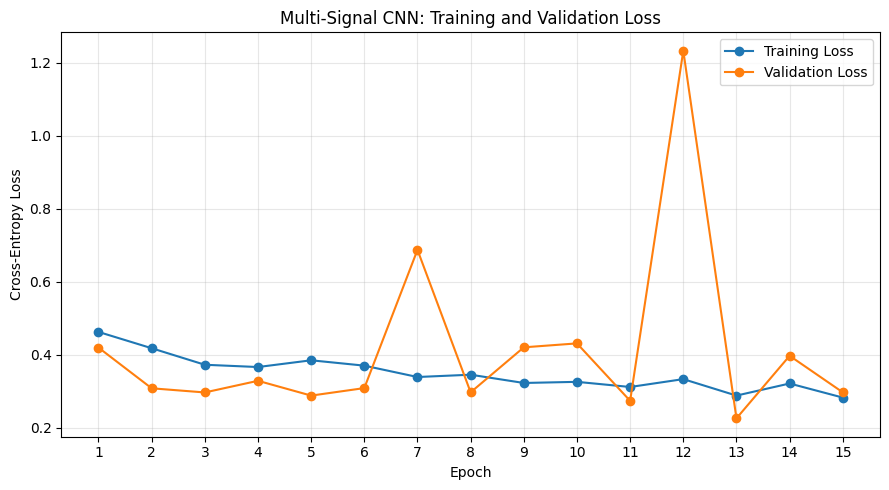

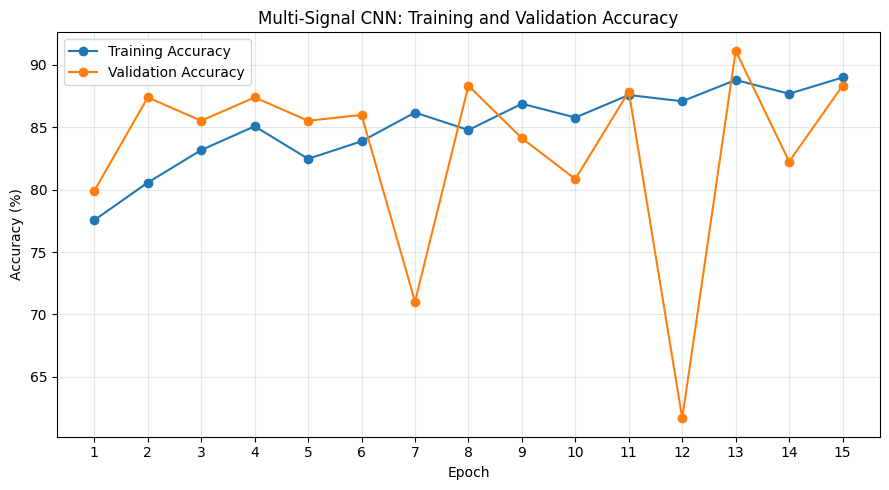

In [ ]:

# ============================================================
# VISUALISE TRAINING AND VALIDATION PERFORMANCE
# ============================================================

epochs = range(1, len(history["train_loss"]) + 1)

# GRAPH 1: LOSS
plt.figure(figsize=(9, 5))

plt.plot(
    epochs,
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.title("Multi-Signal CNN: Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.xticks(list(epochs))
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# GRAPH 2: ACCURACY
plt.figure(figsize=(9, 5))

plt.plot(
    epochs,
    np.array(history["train_accuracy"]) * 100,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs,
    np.array(history["val_accuracy"]) * 100,
    marker="o",
    label="Validation Accuracy"
)

plt.title("Multi-Signal CNN: Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.xticks(list(epochs))
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:

import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from google.colab import drive

# Reconnect Google Drive
drive.mount('/content/drive')

# Project directory
PROJECT_PATH = "/content/drive/MyDrive/ugx-banknote-prototype"

# Load the saved training history
history_path = os.path.join(
    PROJECT_PATH,
    "reports",
    "multisignal_training_history.csv"
)

df_history = pd.read_csv(history_path)

print("Training history restored!")
display(df_history)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training history restored!


,epoch,train_loss,train_accuracy,val_loss,val_accuracy
0,1,0.462670,0.775551,0.419696,0.799065
1,2,0.418003,0.805611,0.308168,0.873832
2,3,0.372687,0.831663,0.296762,0.855140
3,4,0.366442,0.850701,0.328720,0.873832
4,5,0.384917,0.824649,0.288127,0.855140
5,6,0.370253,0.838677,0.308733,0.859813
6,7,0.339091,0.861723,0.687621,0.710280
7,8,0.345408,0.847695,0.297109,0.883178
8,9,0.322746,0.868737,0.420459,0.841121
9,10,0.325851,0.857715,0.431255,0.808411


In [ ]:

history = {
    "train_loss": df_history["train_loss"].tolist(),
    "train_accuracy": df_history["train_accuracy"].tolist(),
    "val_loss": df_history["val_loss"].tolist(),
    "val_accuracy": df_history["val_accuracy"].tolist()
}

print("History variable restored successfully!")
print("Number of epochs:", len(history["train_loss"]))


History variable restored successfully!
Number of epochs: 15


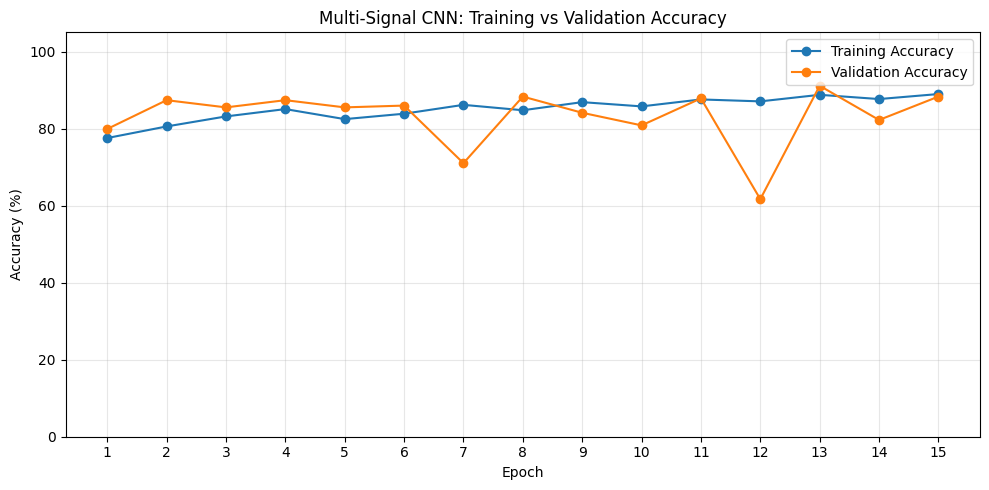

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

epochs = range(1, len(history["train_accuracy"]) + 1)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    np.array(history["train_accuracy"]) * 100,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs,
    np.array(history["val_accuracy"]) * 100,
    marker="o",
    label="Validation Accuracy"
)

plt.title("Multi-Signal CNN: Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.xticks(list(epochs))
plt.ylim(0, 105)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


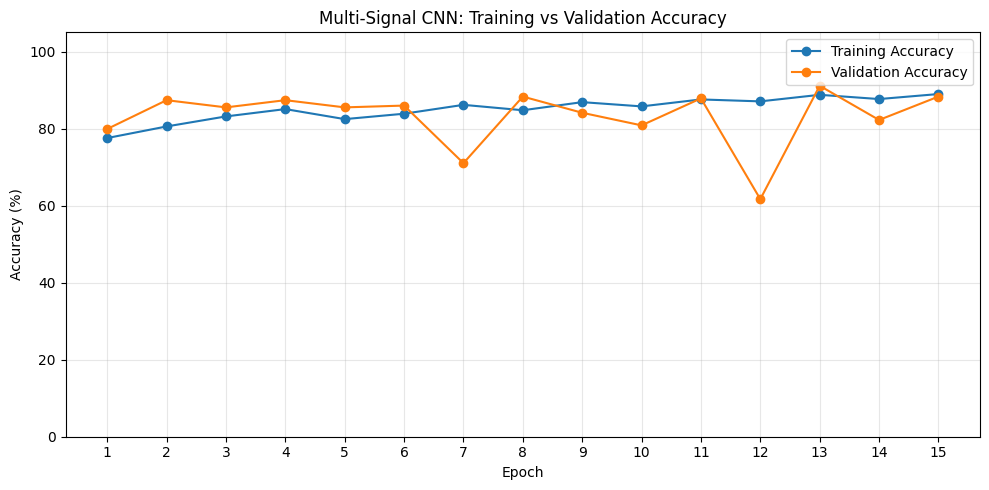

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

epochs = range(1, len(history["train_accuracy"]) + 1)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    np.array(history["train_accuracy"]) * 100,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs,
    np.array(history["val_accuracy"]) * 100,
    marker="o",
    label="Validation Accuracy"
)

plt.title("Multi-Signal CNN: Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.xticks(list(epochs))
plt.ylim(0, 105)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:

print("Model available:", "model" in globals())
print("Validation loader available:", "validation_loader" in globals())
print("Device available:", "device" in globals())


Model available: False
Validation loader available: False
Device available: False


In [ ]:

import torch
import torch.nn as nn

# Individual CNN branch
class CNNBranch(nn.Module):

    def __init__(self, input_channels):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(input_channels, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

    def forward(self, x):
        x = self.features(x)
        x = self.global_pool(x)
        x = torch.flatten(x, 1)
        return x


# Three-stream CNN with feature concatenation
class MultiSignalCNN(nn.Module):

    def __init__(self, num_classes=2):
        super().__init__()

        self.rgb_branch = CNNBranch(input_channels=3)
        self.edge_branch = CNNBranch(input_channels=1)
        self.texture_branch = CNNBranch(input_channels=1)

        self.fusion_size = 64 * 3

        self.classifier = nn.Sequential(
            nn.Linear(self.fusion_size, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, rgb, edges, texture):

        rgb_features = self.rgb_branch(rgb)
        edge_features = self.edge_branch(edges)
        texture_features = self.texture_branch(texture)

        combined_features = torch.cat(
            [rgb_features, edge_features, texture_features],
            dim=1
        )

        output = self.classifier(combined_features)

        return output


print("MultiSignalCNN architecture restored!")


MultiSignalCNN architecture restored!


In [ ]:

import os

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = MultiSignalCNN(num_classes=2).to(device)

best_model_path = os.path.join(
    PROJECT_PATH,
    "models",
    "multisignal_concat_best.pth"
)

checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Successfully restored trained model!")
print("Best epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["val_loss"])
print("Device:", device)


Successfully restored trained model!
Best epoch: 1
Best validation loss: 0.30072963836594163
Device: cpu


Best checkpoint epoch: 1
Best validation loss: 0.30072963836594163

CLASSIFICATION REPORT
              precision    recall  f1-score   support

 Counterfeit     0.8448    0.8596    0.8522       114
     Genuine     0.8367    0.8200    0.8283       100

    accuracy                         0.8411       214
   macro avg     0.8408    0.8398    0.8402       214
weighted avg     0.8410    0.8411    0.8410       214

Balanced Accuracy: 0.8398245614035087
Matthews Correlation Coefficient: 0.6806050292186693


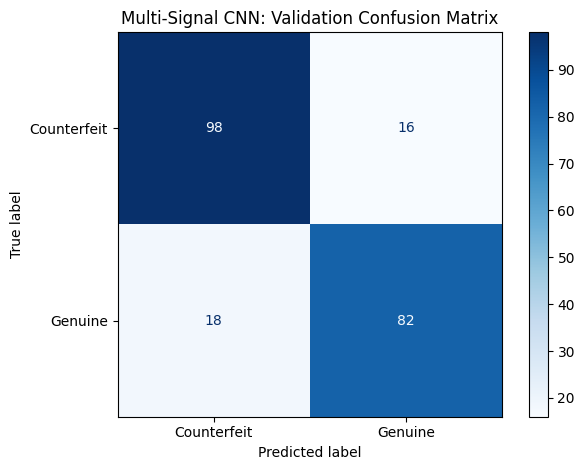

In [ ]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    balanced_accuracy_score,
    matthews_corrcoef
)
import matplotlib.pyplot as plt
import torch

# Restore the best saved checkpoint
checkpoint = torch.load(
    PROJECT_PATH + "/models/multisignal_concat_best.pth",
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for batch in validation_loader:

        rgb = batch["rgb"].to(device)
        edges = batch["edges"].to(device)
        texture = batch["texture"].to(device)
        labels = batch["label"].to(device)

        outputs = model(rgb, edges, texture)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

# Calculate metrics
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=[0, 1]
)

print("Best checkpoint epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["val_loss"])

print("\nCLASSIFICATION REPORT")
print(classification_report(
    all_labels,
    all_predictions,
    labels=[0, 1],
    target_names=["Counterfeit", "Genuine"],
    digits=4
))

print("Balanced Accuracy:",
      balanced_accuracy_score(all_labels, all_predictions))

print("Matthews Correlation Coefficient:",
      matthews_corrcoef(all_labels, all_predictions))

# Visualise confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Counterfeit", "Genuine"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("Multi-Signal CNN: Validation Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:

import os
import pandas as pd
import torch

checkpoint_path = os.path.join(
    PROJECT_PATH,
    "models",
    "multisignal_concat_best.pth"
)

history_path = os.path.join(
    PROJECT_PATH,
    "reports",
    "multisignal_training_history.csv"
)

# Inspect checkpoint
saved_checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

print("CHECKPOINT INVESTIGATION")
print("------------------------")
print("File:", checkpoint_path)
print("File exists:", os.path.exists(checkpoint_path))
print("File size:", os.path.getsize(checkpoint_path), "bytes")
print("Saved epoch:", saved_checkpoint["epoch"])
print("Saved validation loss:", saved_checkpoint["val_loss"])
print("Saved validation accuracy:", saved_checkpoint["val_accuracy"])

# Inspect training history
df = pd.read_csv(history_path)

print("\nTRAINING HISTORY")
print("----------------")
print("Columns:", df.columns.tolist())

print("\nLowest validation loss in CSV:")

best_row = df.loc[df["val_loss"].idxmin()]
print(best_row)

print("\nLast five training records:")
display(df.tail())


CHECKPOINT INVESTIGATION
------------------------
File: /content/drive/MyDrive/ugx-banknote-prototype/models/multisignal_concat_best.pth
File exists: True
File size: 1213593 bytes
Saved epoch: 1
Saved validation loss: 0.30072963836594163
Saved validation accuracy: 0.8411214953271028

TRAINING HISTORY
----------------
Columns: ['epoch', 'train_loss', 'train_accuracy', 'val_loss', 'val_accuracy']

Lowest validation loss in CSV:
epoch             13.000000
train_loss         0.288150
train_accuracy     0.887776
val_loss           0.225799
val_accuracy       0.911215
Name: 12, dtype: float64

Last five training records:


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [ ]:

from pathlib import Path
from datetime import datetime
import torch

models_folder = Path(PROJECT_PATH) / "models"

print("SAVED MODEL CHECKPOINTS")
print("=" * 55)

for file in sorted(models_folder.glob("*.pth")):

    checkpoint_info = torch.load(
        file,
        map_location="cpu",
        weights_only=True
    )

    modified = datetime.fromtimestamp(
        file.stat().st_mtime
    )

    print(f"\nFile: {file.name}")
    print(f"Saved epoch: {checkpoint_info.get('epoch', 'Unknown')}")
    print(f"Validation loss: {checkpoint_info.get('val_loss', 'Unknown')}")
    print(f"Validation accuracy: {checkpoint_info.get('val_accuracy', 'Unknown')}")
    print(f"Last modified: {modified}")


SAVED MODEL CHECKPOINTS

File: baseline_cnn_best.pth
Saved epoch: Unknown
Validation loss: Unknown
Validation accuracy: Unknown
Last modified: 2026-11-09 23:38:48

File: multisignal_concat_best.pth
Saved epoch: 1
Validation loss: 0.30072963836594163
Validation accuracy: 0.8411214953271028
Last modified: 2026-11-12 08:19:01

File: resnet18_feature_extractor_best.pth
Saved epoch: 8
Validation loss: Unknown
Validation accuracy: Unknown
Last modified: 2026-11-10 15:55:00

File: resnet18_finetuned_best.pth
Saved epoch: 9
Validation loss: Unknown
Validation accuracy: Unknown
Last modified: 2026-11-10 18:41:35


In [ ]:

print(df.tail().to_string(index=False))

# Restore the notebook's display function name
from IPython.display import display as show_table

show_table(df)


 epoch  train_loss  train_accuracy  val_loss  val_accuracy
    11    0.311742        0.875752  0.273793      0.878505
    12    0.333301        0.870741  1.233551      0.616822
    13    0.288150        0.887776  0.225799      0.911215
    14    0.321314        0.876754  0.397249      0.822430
    15    0.282683        0.889780  0.297090      0.883178


,epoch,train_loss,train_accuracy,val_loss,val_accuracy
0,1,0.462670,0.775551,0.419696,0.799065
1,2,0.418003,0.805611,0.308168,0.873832
2,3,0.372687,0.831663,0.296762,0.855140
3,4,0.366442,0.850701,0.328720,0.873832
4,5,0.384917,0.824649,0.288127,0.855140
5,6,0.370253,0.838677,0.308733,0.859813
6,7,0.339091,0.861723,0.687621,0.710280
7,8,0.345408,0.847695,0.297109,0.883178
8,9,0.322746,0.868737,0.420459,0.841121
9,10,0.325851,0.857715,0.431255,0.808411


In [ ]:

from google.colab import drive
drive.mount('/content/drive')

import os
import sys
import torch
from torch.utils.data import Dataset, DataLoader
from pathlib import Path

PROJECT_PATH = "/content/drive/MyDrive/ugx-banknote-prototype"

os.chdir(PROJECT_PATH)

if PROJECT_PATH not in sys.path:
    sys.path.insert(0, PROJECT_PATH)

from src.banknote.preprocessing.prepare_streams import (
    prepare_banknote_streams
)

print("Project environment restored!")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project environment restored!


In [ ]:

import numpy as np

class MultiStreamBanknoteDataset(Dataset):

    def __init__(self, split_path):
        self.samples = []

        split_path = Path(split_path)

        for class_name, label in [
            ("counterfeit", 0),
            ("genuine", 1)
        ]:

            class_folder = split_path / class_name

            for image_path in class_folder.glob("*"):
                if image_path.suffix.lower() in [
                    ".jpg", ".jpeg", ".png"
                ]:
                    self.samples.append((image_path, label))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):

        image_path, label = self.samples[index]

        streams = prepare_banknote_streams(
            str(image_path),
            target_size=224
        )

        rgb = torch.from_numpy(
            streams["rgb"].transpose(2, 0, 1).copy()
        ).float() / 255.0

        edges = torch.from_numpy(
            streams["edges"][None, :, :].copy()
        ).float() / 255.0

        texture = torch.from_numpy(
            streams["texture"][None, :, :].copy()
        ).float() / 255.0

        return {
            "rgb": rgb,
            "edges": edges,
            "texture": texture,
            "label": torch.tensor(label, dtype=torch.long)
        }


# Locate dataset
matches = list(
    Path("data/raw").glob(
        "Ugandan banknote*/labelled_ugandan_banknote_dataset_clean"
    )
)

if len(matches) != 1:
    raise RuntimeError(
        f"Expected one dataset folder, found {len(matches)}"
    )

DATASET_PATH = matches[0]

# Recreate datasets
train_dataset = MultiStreamBanknoteDataset(
    DATASET_PATH / "splits" / "train_set"
)

validation_dataset = MultiStreamBanknoteDataset(
    DATASET_PATH / "splits" / "validation_set"
)

test_dataset = MultiStreamBanknoteDataset(
    DATASET_PATH / "splits" / "test_set"
)

# Recreate loaders
BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Data pipeline restored!")
print("Training images:", len(train_dataset))
print("Validation images:", len(validation_dataset))
print("Testing images:", len(test_dataset))


Data pipeline restored!
Training images: 998
Validation images: 214
Testing images: 214


In [ ]:

batch = next(iter(validation_loader))

print("RGB:", batch["rgb"].shape)
print("Edges:", batch["edges"].shape)
print("Texture:", batch["texture"].shape)
print("Labels:", batch["label"].shape)

print("\nModel available:", "model" in globals())
print("Validation loader available:", "validation_loader" in globals())


RGB: torch.Size([8, 3, 224, 224])
Edges: torch.Size([8, 1, 224, 224])
Texture: torch.Size([8, 1, 224, 224])
Labels: torch.Size([8])

Model available: True
Validation loader available: True


In [ ]:
from pathlib import Path
import zipfile

project = Path("/content/drive/MyDrive/ugx-banknote-prototype")
archive = Path("/content/drive/MyDrive/Banknote_project_review.zip")

# Include the code, project setup, split information if present,
# and the checkpoint and history we're investigating.
items = [
    "README.md",
    ".gitignore",
    "requirements.txt",
    "pyproject.toml",
    "src",
    "tests",
    "configs",
    "data/splits",
    "models/multisignal_concat_best.pth",
    "reports/multisignal_training_history.csv",
]

with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as z:
    for item in items:
        path = project / item

        if path.is_file():
            z.write(path, arcname=item)

        elif path.is_dir():
            for file in path.rglob("*"):
                if not file.is_file():
                    continue
                if ".venv" in file.parts or "__pycache__" in file.parts:
                    continue
                if file.suffix == ".pyc":
                    continue

                z.write(file, arcname=file.relative_to(project))

print("Created:", archive)
print("Size in MB:", round(archive.stat().st_size / (1024 * 1024), 2))

Created: /content/drive/MyDrive/Banknote_project_review.zip
Size in MB: 1.03


In [ ]:
from google.colab import files
from pathlib import Path
import zipfile

uploaded = files.upload()  # Choose Banknote_phase1_patch.zip
patch_name = next(iter(uploaded))

with zipfile.ZipFile(patch_name) as patch:
    patch.extractall(Path(PROJECT_PATH))

Saving Banknote_phase1_patch.zip to Banknote_phase1_patch (1).zip


In [2]:
from google.colab import drive
from pathlib import Path
import zipfile

drive.mount("/content/drive")

PROJECT_PATH = Path("/content/drive/MyDrive/ugx-banknote-prototype")
if not PROJECT_PATH.is_dir():
    raise FileNotFoundError(f"Project folder not found: {PROJECT_PATH}")

patch_path = Path(patch_name) if "patch_name" in globals() else Path("Banknote_phase1_patch.zip")
if not patch_path.is_file():
    raise FileNotFoundError(f"Patch ZIP not found: {patch_path}")

with zipfile.ZipFile(patch_path) as patch:
    files = [name for name in patch.namelist() if not name.endswith("/")]
    conflicts = [name for name in files if (PROJECT_PATH / name).exists()]
    if conflicts:
        raise FileExistsError(f"These files already exist; stopping to avoid overwriting: {conflicts}")
    patch.extractall(PROJECT_PATH)

print("Patch extracted to:", PROJECT_PATH)
print("Trainer found:", (PROJECT_PATH / "src/banknote/training/train_multisignal.py").is_file())
print("Data folders found:", list((PROJECT_PATH / "data/raw").glob("Ugandan banknote*/labelled_ugandan_banknote_dataset_clean")))

MessageError: Error: credential propagation was unsuccessful

In [1]:
%cd /content/drive/MyDrive/ugx-banknote-prototype
!python -m src.banknote.training.train_multisignal --run-id concat-seed42 --seed 42

/content/drive/MyDrive/ugx-banknote-prototype
Run: concat-seed42
Dataset: labelled_ugandan_banknote_dataset_clean
Device: cuda; seed: 42; epochs: 15
Artifacts: /content/drive/MyDrive/ugx-banknote-prototype/runs/multisignal/concat-seed42
Epoch 01/15 | train loss 0.4692, acc 0.7695 | val loss 0.3302, acc 0.8551 | best checkpoint updated
Epoch 02/15 | train loss 0.4156, acc 0.8086 | val loss 0.3161, acc 0.8551 | best checkpoint updated
Epoch 03/15 | train loss 0.3661, acc 0.8467 | val loss 0.4988, acc 0.7243
